# metagenomics project*
Analyzing differential abundance of 2 different treatments of foliar endophytes: dominant (*Alternaria*, *suite*, or *both*)


## data:
- Harrison et al. 2021, *ISME J* (https://doi.org/10.1038/s41396-021-00964-4); code + metadata: https://github.com/JHarrisonEcoEvo/RareMicrobes
- this is the **preliminary MiSeq run** (2 x 250 bp, paired end), NOT the NovaSeq data analyzed in the paper
- **16S** V4 region, primers 515F / 806R, 197 wells + 2 positive controls (one with PNA clamps, one without)
- **ITS** ITS1 region, primers ITS1F / ITS2, 192 wells + 1 positive control
- file names are `plate-well`: plates 1 & 2 are 96 wells each, plate 3 has 5 wells (the `_noPNA` samples)
- every read header has the same flowcell ID (`M02288:45:000000000-B6D76`), so **all of it is one sequencing run**
- treatments (2 x 2 factorial), from the `treament` column of `trait_and_treatment_data.csv`:
    - `treated` / `untreated` = rare microbe inoculum sprayed on or not
    - `plus` / `neg` = *A. fulva* (= *Alternaria fulva*, = *Undifilum*) present, or reduced by cutting embryos out of the seed coat
    - `control...` = agar controls (embryos planted with sterile agar or *A. fulva* agar)

In [2]:
# folder/data infrastructure + ALL pipeline parameters
# every path/threshold used further down is set here, so change things HERE, not inside the pipeline cells

## ---- input paths (raw data: only ever read, never written to) ----
projDir     <- path.expand('~/Desktop/academia/BIOL495_metagenomics/metagenomicsProj')  # path.expand turns ~ into the full path; cutadapt can't read '~'
seqPath.16s <- file.path(projDir, 'MiSeq data/809 (Copy 1)/Harrison_et_al_endophytes_in_ASLE/HarrisonASLE_16s')
seqPath.ITS <- file.path(projDir, 'MiSeq data/809 (Copy 1)/Harrison_et_al_endophytes_in_ASLE/HarrisonASLE_ITS')

## ---- metadata (downloaded from the authors' GitHub repo in the metadata cell) ----
metaPath <- file.path(projDir, 'data/raw/metadata')
keyPath  <- file.path(metaPath, 'Sample_Well_Key_includesQuants.csv')  # plate/well -> sample name (MiSeq run)
trtPath  <- file.path(metaPath, 'trait_and_treatment_data.csv')         # plant number -> treatment
repoURL  <- 'https://raw.githubusercontent.com/JHarrisonEcoEvo/RareMicrobes/main/data/'

## ---- output paths (everything the pipeline makes goes here) ----
procPath <- file.path(projDir, 'data/processed')   # intermediate fastqs, tables, R objects
resPath  <- file.path(projDir, 'results')          # final tables / figures

## ---- tools & compute ----
cutadaptPath <- '/home/sonora/.pixi/bin/cutadapt'  # v5.2; full path because R doesn't always see the same PATH as your terminal
vsearchPath  <- '/home/sonora/.pixi/bin/vsearch'   # NOT installed yet, see install cell
blastnPath   <- '/home/sonora/.pixi/bin/blastn'    # NOT installed yet, see install cell (part of the BLAST+ suite)
nThreads     <- 8                                  # this machine has 16 cores
randomSeed   <- 495

## ---- primers (both are still on the reads, checked in the primer section) ----
FWD.16s <- 'GTGYCAGCMGCCGCGGTAA'      # 515F (19 nt)  - Y, M, N, V, W are IUPAC ambiguity codes
REV.16s <- 'GGACTACNVGGGTWTCTAAT'     # 806R (20 nt)
FWD.ITS <- 'CTTGGTCATTTAGAGGAAGTAA'   # ITS1F (22 nt)
REV.ITS <- 'GCTGCGTTCTTCATCGATGC'     # ITS2 (20 nt)

## ---- filter & trim ----
truncLen.16s <- c(250, 250)  # fwd, rvr: where to cut reads. CHECK against the full aggregate quality plots and change if needed
                             # must keep enough overlap to merge: (240-19) + (160-20) = 361 bp of read for a ~253 bp V4 amplicon -> ~108 bp overlap
maxEE.16s    <- c(2, 2)      # max "expected errors" allowed per read (fwd, rvr); reads above this are thrown out
maxEE.ITS    <- c(2, 2)
truncQ       <- 2            # cut a read at the first base with quality <= 2 (dada2 default)
minLen.ITS   <- 50           # ITS reads aren't truncated to a fixed length, so drop very short leftovers instead

## ---- error learning & denoising (stage 2) ----
nbasesLearn <- 1e8           # number of bases used to learn the error model (dada2 default)
poolMethod  <- 'pseudo'      # FALSE = each sample alone; 'pseudo' = share info across samples (better for rare taxa, slower)

## ---- merging (stage 2) ----
minOverlap  <- 4            # dada2 default
maxMismatch <- 0             # dada2 default

## ---- sequence table & chimeras (stage 2) ----
seqLenRange.16s <- 250:256   # expected V4 length after primer removal is ~253 bp; ASVs far outside are probably non-specific
chimeraMethod   <- 'consensus'

## ---- taxonomy (stage 3) ----
dbPath        <- file.path(projDir, 'data/databases')
silvaURL      <- 'https://zenodo.org/records/14169026/files/'                     # SILVA 138.2 formatted for dada2 (Zenodo)
silvaTrainset <- file.path(dbPath, 'silva_nr99_v138.2_toGenus_trainset.fa.gz')   # training set for the classifier (Kingdom -> Genus)
silvaSpecies  <- file.path(dbPath, 'silva_v138.2_assignSpecies.fa.gz')           # exact-match species file
uniteRef      <- file.path(dbPath, 'sh_general_release_dynamic_all_19.02.2025.fasta')             # downloaded by hand, see the taxonomy section
minBoot       <- 50          # min bootstrap confidence (out of 100) to accept a taxonomic rank (dada2 default)

## ---- inoculum / A. fulva reference sequences from the authors' repo (stage 3) ----
refPath     <- file.path(projDir, 'data/raw/reference')
inocRef.16s <- file.path(refPath, 'all_16S_OTUs_inoculum_NS_and_Miseq_NAMES_OF_OTUS_NOTSAME_AS_NS.fasta')  # 260 inoculum 16S OTUs
inocRef.ITS <- file.path(refPath, 'all_ITS_OTUs_inoculum_NS_and_MiseqNAMES_OF_OTUS_NOTSAME_AS_NS.fasta')   # 20 inoculum ITS OTUs
afulvaRef   <- file.path(refPath, 'alternaria_fulva.fasta')                                                # A. fulva ITS (GenBank JX827264.1)
minIdentity <- 97            # % identity needed to call an ASV a "match" to a reference sequence (classic OTU cutoff)
vsearchReportId <- 0.80      # vsearch reports the best hit down to 80% identity, so near-misses are visible too
queryCov        <- 0.90      # at least 90% of the ASV has to be in the alignment (stops short partial overlaps scoring 100%)

## ---- contaminant removal (stage 3) ----
contamThreshold <- 0.05      # paper: drop ASVs with > 5% of their reads in the negative control

set.seed(randomSeed)

list.files(seqPath.16s)  # sanity check
list.files(seqPath.ITS)  # sanity check

  [1] "1-a1_S200_L001_R1_001.fastq.gz"                 "1-a1_S200_L001_R2_001.fastq.gz"                 "1-a10_S272_L001_R1_001.fastq.gz"               
  [4] "1-a10_S272_L001_R2_001.fastq.gz"                "1-a11_S280_L001_R1_001.fastq.gz"                "1-a11_S280_L001_R2_001.fastq.gz"               
  [7] "1-a12_S288_L001_R1_001.fastq.gz"                "1-a12_S288_L001_R2_001.fastq.gz"                "1-a2_S208_L001_R1_001.fastq.gz"                
 [10] "1-a2_S208_L001_R2_001.fastq.gz"                 "1-a3_S216_L001_R1_001.fastq.gz"                 "1-a3_S216_L001_R2_001.fastq.gz"                
 [13] "1-a4_S224_L001_R1_001.fastq.gz"                 "1-a4_S224_L001_R2_001.fastq.gz"                 "1-a5_S232_L001_R1_001.fastq.gz"                
 [16] "1-a5_S232_L001_R2_001.fastq.gz"                 "1-a6_S240_L001_R1_001.fastq.gz"                 "1-a6_S240_L001_R2_001.fastq.gz"                
 [19] "1-a7_S248_L001_R1_001.fastq.gz"                 "1-a7_S248_L001_R2_001.fast

### installs/library loading etc:
# NEEDS A DEMULTIPLEXING TOOL?
- no bc if there's a plate/well key then the samples are inherently not multiplexed
    - SOMEONE PLS CONFIRM
    - **confirmed:** there is one R1/R2 file pair per well, so the sequencing facility already demultiplexed it. The number at the end of each read header (e.g. `1:N:0:272`) is the sample index the facility used
- If we get the NovaSeq data from J. Harrison, then we will need a de-multiplexing step

In [ ]:
# dada2, phyloseq, ShortRead and Biostrings are Bioconductor packages, so install.packages() can't find them,
# and package names need quotes. All of these are already installed on this machine (dada2 1.30.0, phyloseq 1.46.0),
# so you only need this cell on a new computer: uncomment and run.
# install.packages("BiocManager")
# BiocManager::install(c("dada2", "phyloseq", "ShortRead", "Biostrings"))
# install.packages("ggplot2")

# ---- command-line tools (not R packages: installed from a terminal, NOT from R) ----
# cutadapt is already installed with pixi (~/.pixi/bin/cutadapt). vsearch and BLAST+ are NOT installed yet.
# They come from the bioconda channel. To install them the same way, run in a terminal:
#     pixi global install --channel conda-forge --channel bioconda vsearch
#     pixi global install --channel conda-forge --channel bioconda blast
# vsearch = fast open-source search/clustering of amplicon sequences (what the paper used for merging, chimeras and OTU matching)
# blastn  = NCBI BLAST for nucleotides, e.g. to double-check what an unassigned ASV is

In [3]:
library(dada2)
library(phyloseq)
library(ggplot2)
library(ShortRead)    # readFastq(), used to count primers in reads
library(Biostrings)   # DNA string tools (reverse complements etc.)

# record versions, for reproducibility
packageVersion("dada2")
system2(cutadaptPath, args = "--version", stdout = TRUE)

# command-line tools: print the version if installed, otherwise a warning
# vsearch IS needed (inoculum matching step, stage 3); blastn is optional (manual checks)
checkTool <- function(path, versionArg) {
    if (file.exists(path)) {
        system2(path, args = versionArg, stdout = TRUE, stderr = TRUE)[1]
    } else {
        warning(paste(basename(path), "not found at", path, "- see the install cell"))
    }
}
checkTool(vsearchPath, "--version")
checkTool(blastnPath,  "-version")

# make output folders (raw data folders are never written to)
dir.create(metaPath, recursive = TRUE, showWarnings = FALSE)
dir.create(procPath, recursive = TRUE, showWarnings = FALSE)
dir.create(resPath,  recursive = TRUE, showWarnings = FALSE)

Loading required package: Rcpp
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind, colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find, get, grep, grepl, intersect, is.unsorted,
    lapply, Map, mapply, match, mget, order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort, table, tapply, union,
    unique, unsplit, which.max, which.min

Loading required package: BiocParallel
Loading required package: Biostrings
Loading required package: S4Vectors
Loading required package: stats4

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges

Warning message:
In checkTool(blastnPath, "-version") :
  blastn not found at /home/sonora/.pixi/bin/blastn - see the install cell


### demultiplexing?

In [ ]:
# I DONT THINK THIS IS NEEDED -SP
# confirmed not needed, see the note above

### extracting sample names

In [5]:
# Forward and reverse fastq filenames have format:  plate-well(-16S)_S##_L001_R1_001.fastq(.gz)
# pattern is "_R1_001.fastq" with NO ".gz" on purpose: ITS-Positive-Control R1 is not gzipped but its R2 is,
# so ".fastq.gz" would skip that R1 and the forward & reverse lists would no longer line up
fnFs.16s <- sort(list.files(seqPath.16s, pattern = "_R1_001.fastq", full.names = TRUE))
fnRs.16s <- sort(list.files(seqPath.16s, pattern = "_R2_001.fastq", full.names = TRUE))

fnFs.ITS <- sort(list.files(seqPath.ITS, pattern = "_R1_001.fastq", full.names = TRUE))
fnRs.ITS <- sort(list.files(seqPath.ITS, pattern = "_R2_001.fastq", full.names = TRUE))


# Extract sample names: "1-a1-16S_S1_L001_R1_001.fastq" -> "1-a1",  "1-a1_S200_L001_R1_001.fastq.gz" -> "1-a1"
# (the old version split on "L001", which left "-16S_S1_" stuck on the end, so 16S and ITS names didn't match each other or the key)
getSampleNames <- function(fn) {
    nm <- sub("_S[0-9]+_L001_R[12]_001\\.fastq(\\.gz)?$", "", basename(fn))  # drop everything from "_S##" onward
    nm <- sub("-16S$", "", nm)                                                # drop the "-16S" tag so 16S & ITS names match
    return(nm)
}

sample.names.16s <- getSampleNames(fnFs.16s)
sample.names.ITS <- getSampleNames(fnFs.ITS)

# stop with an error if forward and reverse files are not in the same order
stopifnot(identical(sample.names.16s, getSampleNames(fnRs.16s)))
stopifnot(identical(sample.names.ITS, getSampleNames(fnRs.ITS)))

length(sample.names.16s)  # expect 199 (197 wells + 2 positive controls)
length(sample.names.ITS)  # expect 193 (192 wells + 1 positive control)
print(sample.names.16s)
print(sample.names.ITS)

  [1] "1-a1"                     "1-a10"                   
  [3] "1-a11"                    "1-a12"                   
  [5] "1-a2"                     "1-a3"                    
  [7] "1-a4"                     "1-a5"                    
  [9] "1-a6"                     "1-a7"                    
 [11] "1-a8"                     "1-a9"                    
 [13] "1-b1"                     "1-b10"                   
 [15] "1-b11"                    "1-b12"                   
 [17] "1-b2"                     "1-b3"                    
 [19] "1-b4"                     "1-b5"                    
 [21] "1-b6"                     "1-b7"                    
 [23] "1-b8"                     "1-b9"                    
 [25] "1-c1"                     "1-c10"                   
 [27] "1-c11"                    "1-c12"                   
 [29] "1-c2"                     "1-c3"                    
 [31] "1-c4"                     "1-c5"                    
 [33] "1-c6"                     "1-c7" 

### sample metadata
Two tables from the authors' repo (`data/` folder), joined in 2 steps:
1. **`Sample_Well_Key_includesQuants.csv`**: plate + well -> `sampleName`. Most names are a plant number, sometimes with a letter (`31a`, `31b`). Lettered names are repeated samples of the same plant, and `_noPNA` ones were amplified without PNA clamps. PNA clamps are short blocking molecules that stop the primers amplifying plant chloroplast/mitochondria DNA. Other names: `Inoculum1a`... (the sprayed microbe mix), `deadly` / `Undifilum` / `black` / `fuzzy` (cultured isolates), and `neg_control`.
2. **`trait_and_treatment_data.csv`**: plant number -> treatment (`treament` column, typo in the original).

The positive controls (`16S-Positive-Control...`, `ITS-Positive-Control`) aren't in the key, so they're labelled from their file names.

The authors' old scripts (`oldscripts/16ScutToBacteria_97otus.R`) join the MiSeq data the same way: plate.well -> key -> sample name.

In [6]:
# download the 2 metadata tables once (skipped if they're already there)
for (f in c(basename(keyPath), basename(trtPath))) {
    dest <- file.path(metaPath, f)
    if (!file.exists(dest)) download.file(paste0(repoURL, f), dest)
}

# build one row of metadata per sequenced sample
makeSampleTable <- function(sampleNames, keyPath, trtPath) {
    # plate/well key. fileEncoding removes a hidden character at the start of the file; strip.white fixes "black " -> "black"
    key <- read.csv(keyPath, fileEncoding = "UTF-8-BOM", strip.white = TRUE)
    key <- key[key$sampleName != "", c("sampleName", "plate", "well")]   # drop the empty last row and the duplicate well column
    key$sampleID <- paste(key$plate, key$well, sep = "-")              # "1-a1", same style as the fastq names

    # treatment table: keep only what we need, fix the column name typo
    trt <- read.csv(trtPath)
    trt <- data.frame(plant = trt$plant, treatment = trt$treament, plantStatus = trt$status)

    samp <- data.frame(sampleID = sampleNames)
    samp <- merge(samp, key, by = "sampleID", all.x = TRUE, sort = FALSE)

    # what kind of sample is each one?
    samp$sampleType <- "plant"
    samp$sampleType[grepl("^Inoculum", samp$sampleName)] <- "inoculum"
    samp$sampleType[samp$sampleName %in% c("deadly", "Undifilum", "black", "fuzzy")] <- "isolate"
    samp$sampleType[samp$sampleName %in% "neg_control"] <- "negControl"
    samp$sampleType[grepl("Positive-Control", samp$sampleID)] <- "posControl"

    # plant number = the digits at the start of the name ("31a" -> 31, "134c_noPNA" -> 134)
    samp$plant <- NA
    isPlant <- samp$sampleType == "plant"
    samp$plant[isPlant] <- as.integer(sub("^([0-9]+).*$", "\\1", samp$sampleName[isPlant]))
    samp$PNA <- !grepl("noPNA", samp$sampleName) & !grepl("Positive-Control$", samp$sampleID)  # the 16S pos. control without "-PNA" had no clamps

    samp <- merge(samp, trt, by = "plant", all.x = TRUE, sort = FALSE)

    # split the treatment code into the 2 experimental factors
    samp$inoculum <- NA
    samp$inoculum[grepl("^treated", samp$treatment)] <- "inoculated"
    samp$inoculum[grepl("^untreated|^control", samp$treatment)] <- "not_inoculated"
    samp$Afulva <- NA
    samp$Afulva[grepl("plus$", samp$treatment, ignore.case = TRUE)] <- "present"
    samp$Afulva[grepl("neg$",  samp$treatment, ignore.case = TRUE)] <- "reduced"
    samp$agarControl <- grepl("control", samp$treatment, ignore.case = TRUE)

    # put rows back in the same order as the fastq files, and use sampleID as row names
    samp <- samp[match(sampleNames, samp$sampleID), ]
    rownames(samp) <- samp$sampleID
    return(samp)
}

sampData.16s <- makeSampleTable(sample.names.16s, keyPath, trtPath)
sampData.ITS <- makeSampleTable(sample.names.ITS, keyPath, trtPath)

# sanity checks: every row should have a sample type, and look at how many samples per treatment
table(sampData.16s$sampleType, useNA = "ifany")
table(sampData.16s$treatment,  useNA = "ifany")   # plants with NA here are in the key but not the treatment table
head(sampData.16s)

write.csv(sampData.16s, file.path(procPath, "sampleData_16S.csv"), row.names = FALSE)
write.csv(sampData.ITS, file.path(procPath, "sampleData_ITS.csv"), row.names = FALSE)

trying URL 'https://raw.githubusercontent.com/JHarrisonEcoEvo/RareMicrobes/main/data/Sample_Well_Key_includesQuants.csv'
Content type 'text/plain; charset=utf-8' length 8816 bytes
downloaded 8816 bytes

trying URL 'https://raw.githubusercontent.com/JHarrisonEcoEvo/RareMicrobes/main/data/trait_and_treatment_data.csv'
Content type 'text/plain; charset=utf-8' length 97801 bytes (95 KB)
downloaded 95 KB



## Plotting aggregate quality scores of fwd & rvr reads

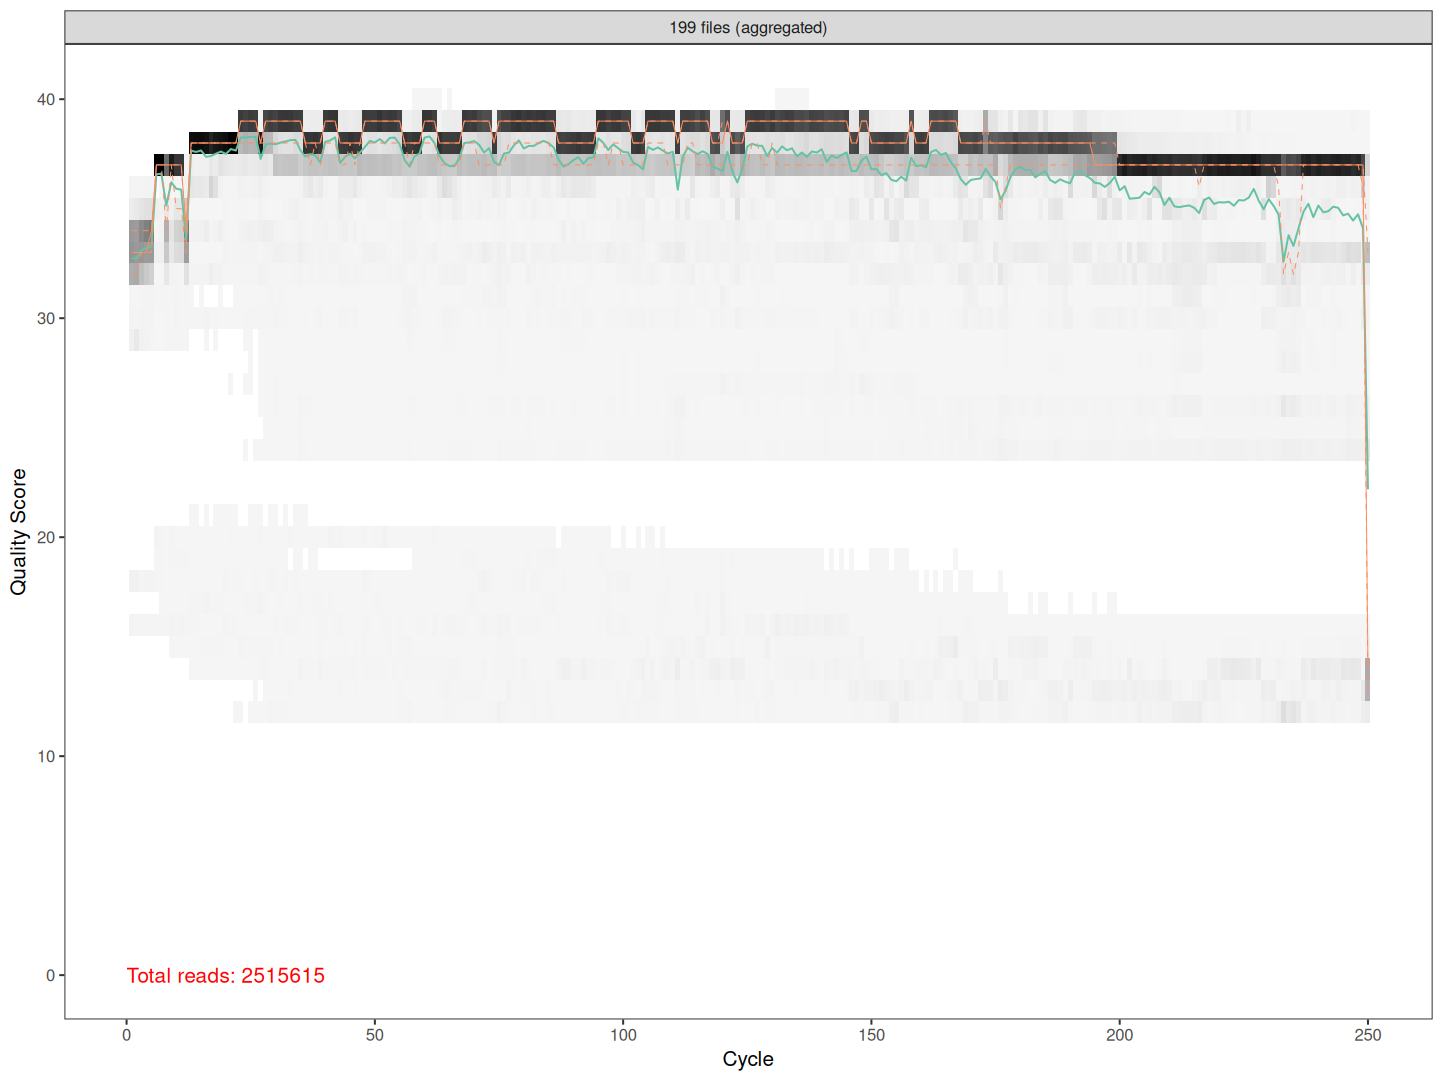

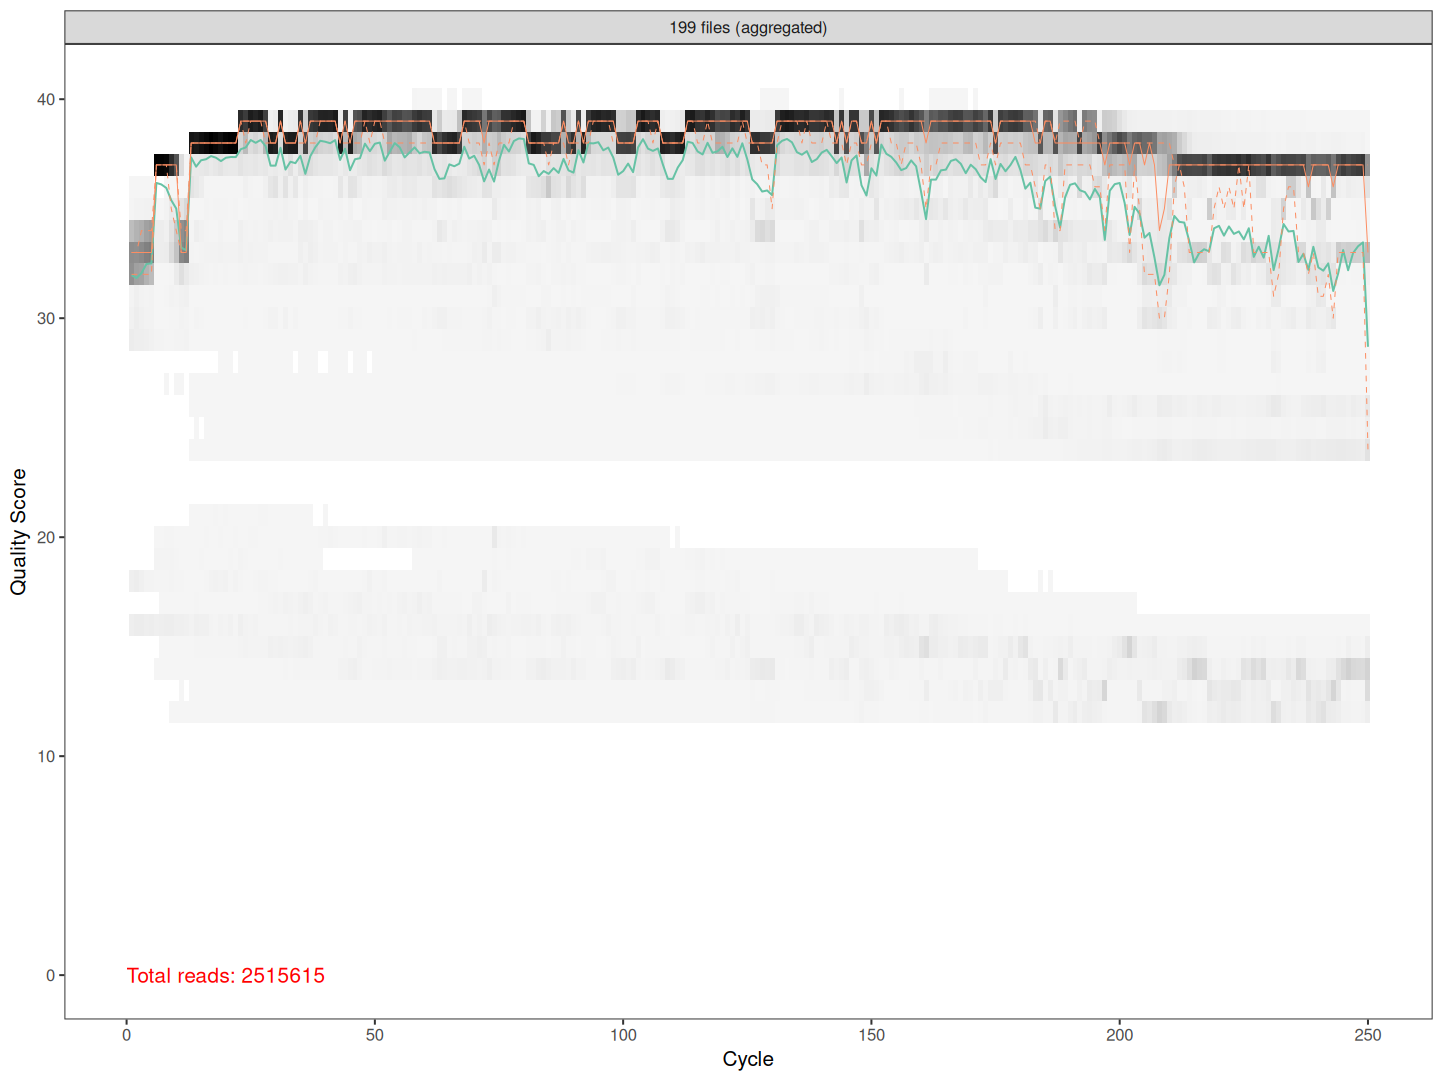

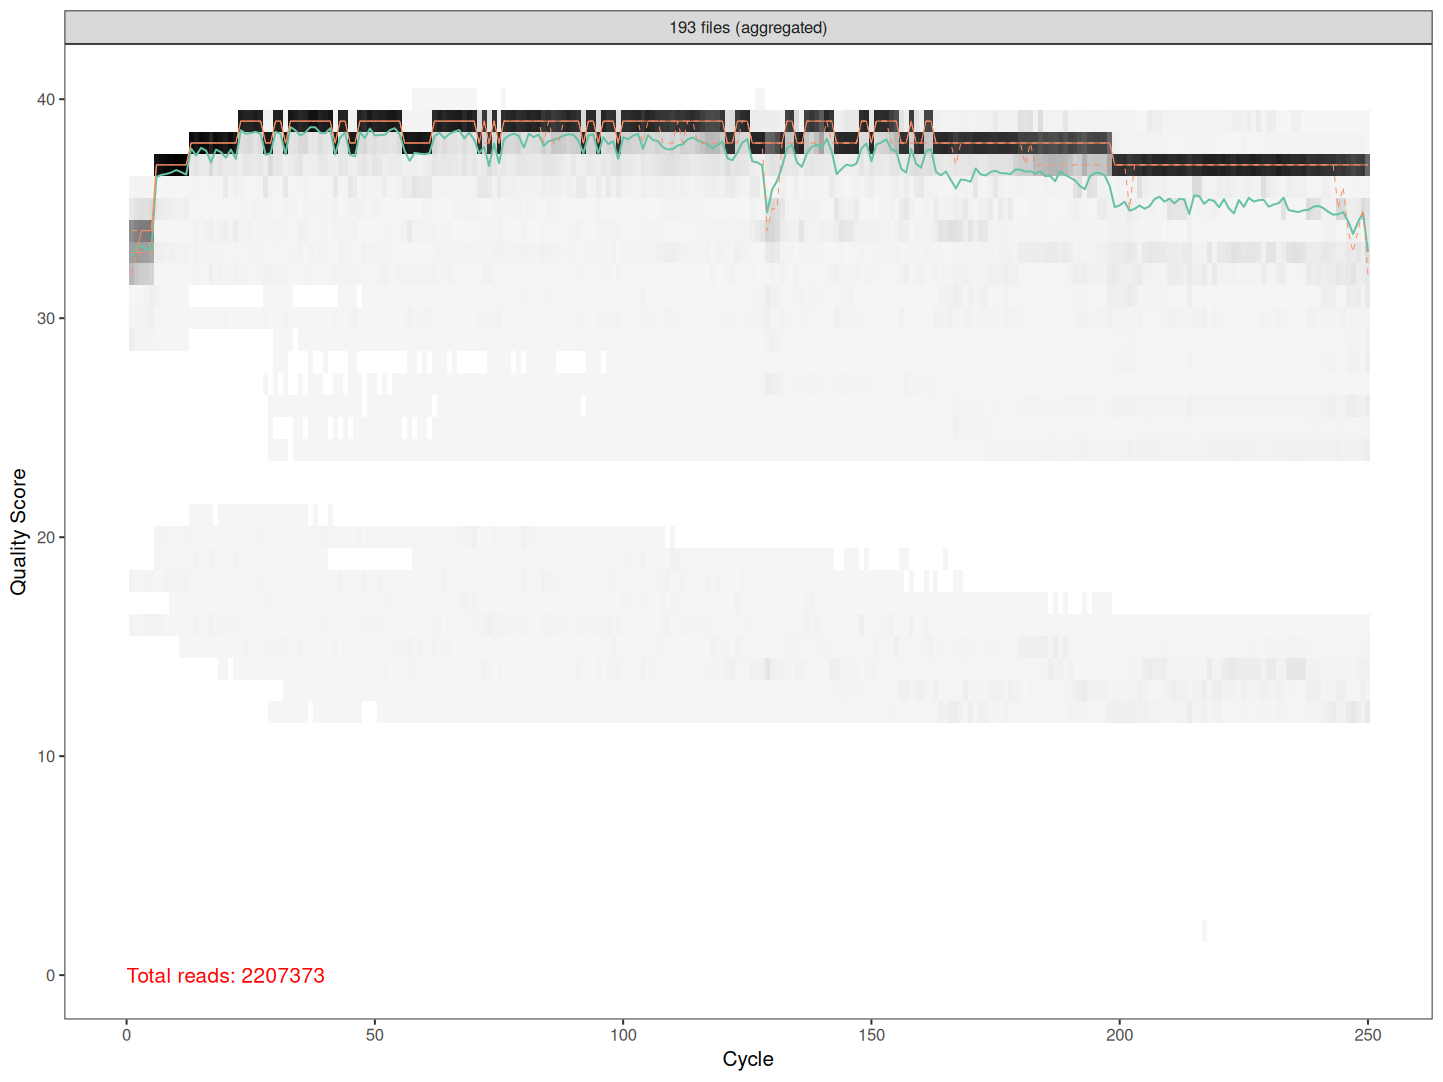

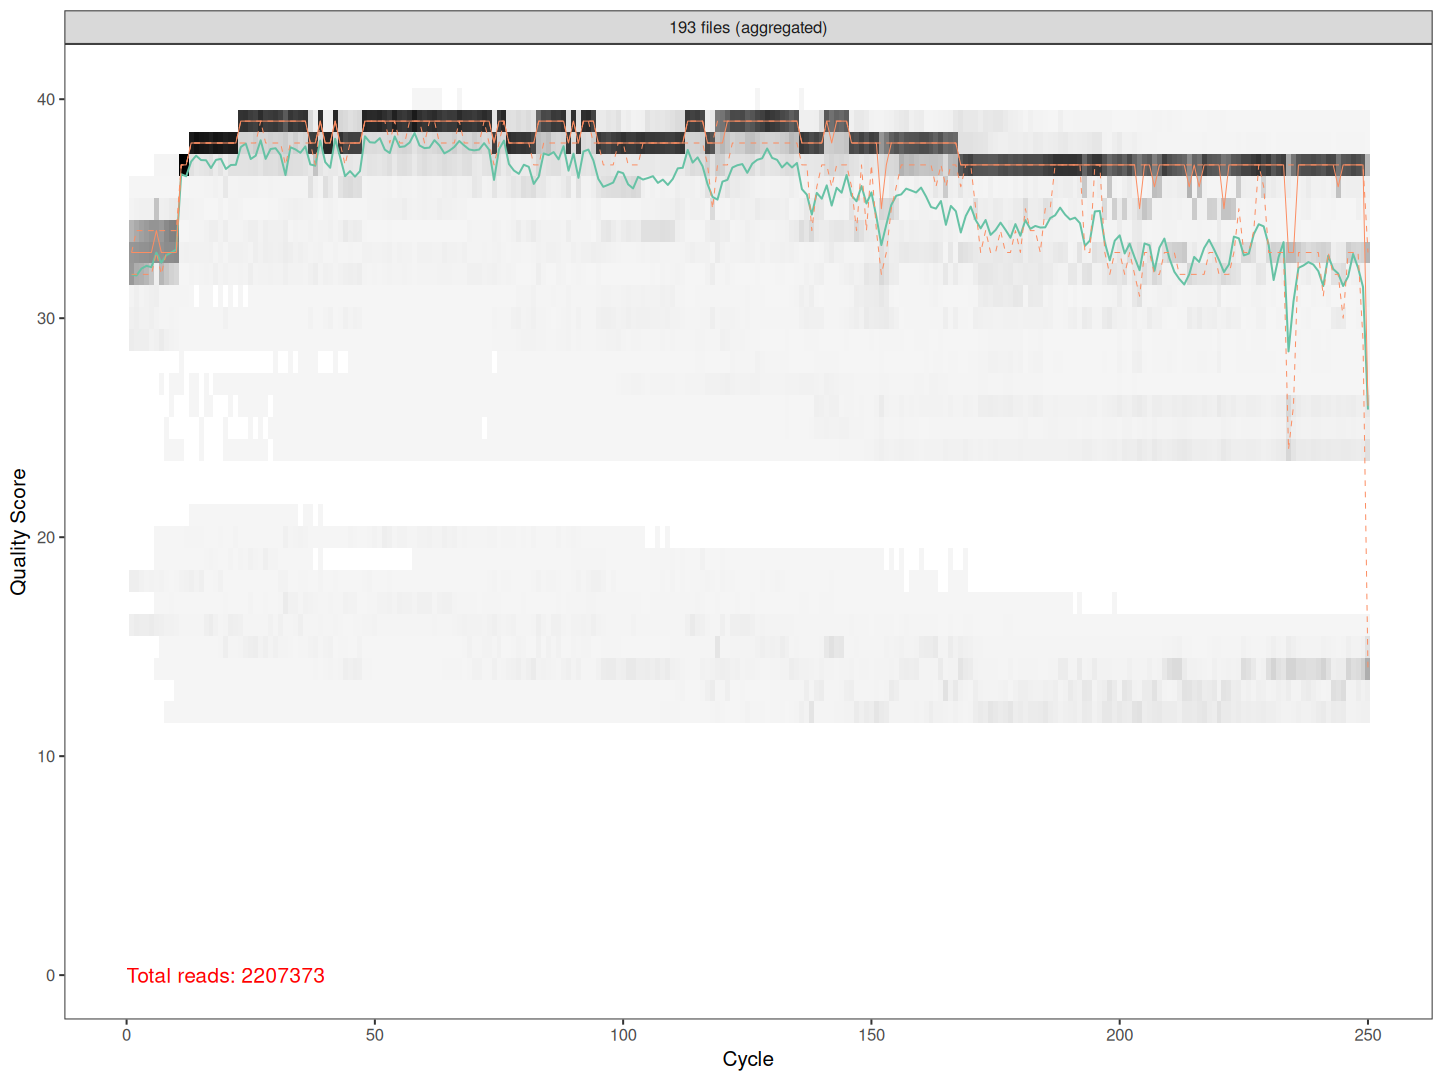

In [7]:
plotQualityProfile(fnFs.16s, aggregate = TRUE)
plotQualityProfile(fnRs.16s, aggregate = TRUE)
plotQualityProfile(fnFs.ITS, aggregate = TRUE)
plotQualityProfile(fnRs.ITS, aggregate = TRUE)
# DO NOT RUN THIS IF YOU ARE IN A RUSH, run cell below as test
# use THESE plots (all files) to pick truncLen.16s in the parameter cell: cut where the green mean line drops below ~Q30

cutoff: 240 fwd 

cutoff: 200 rvr

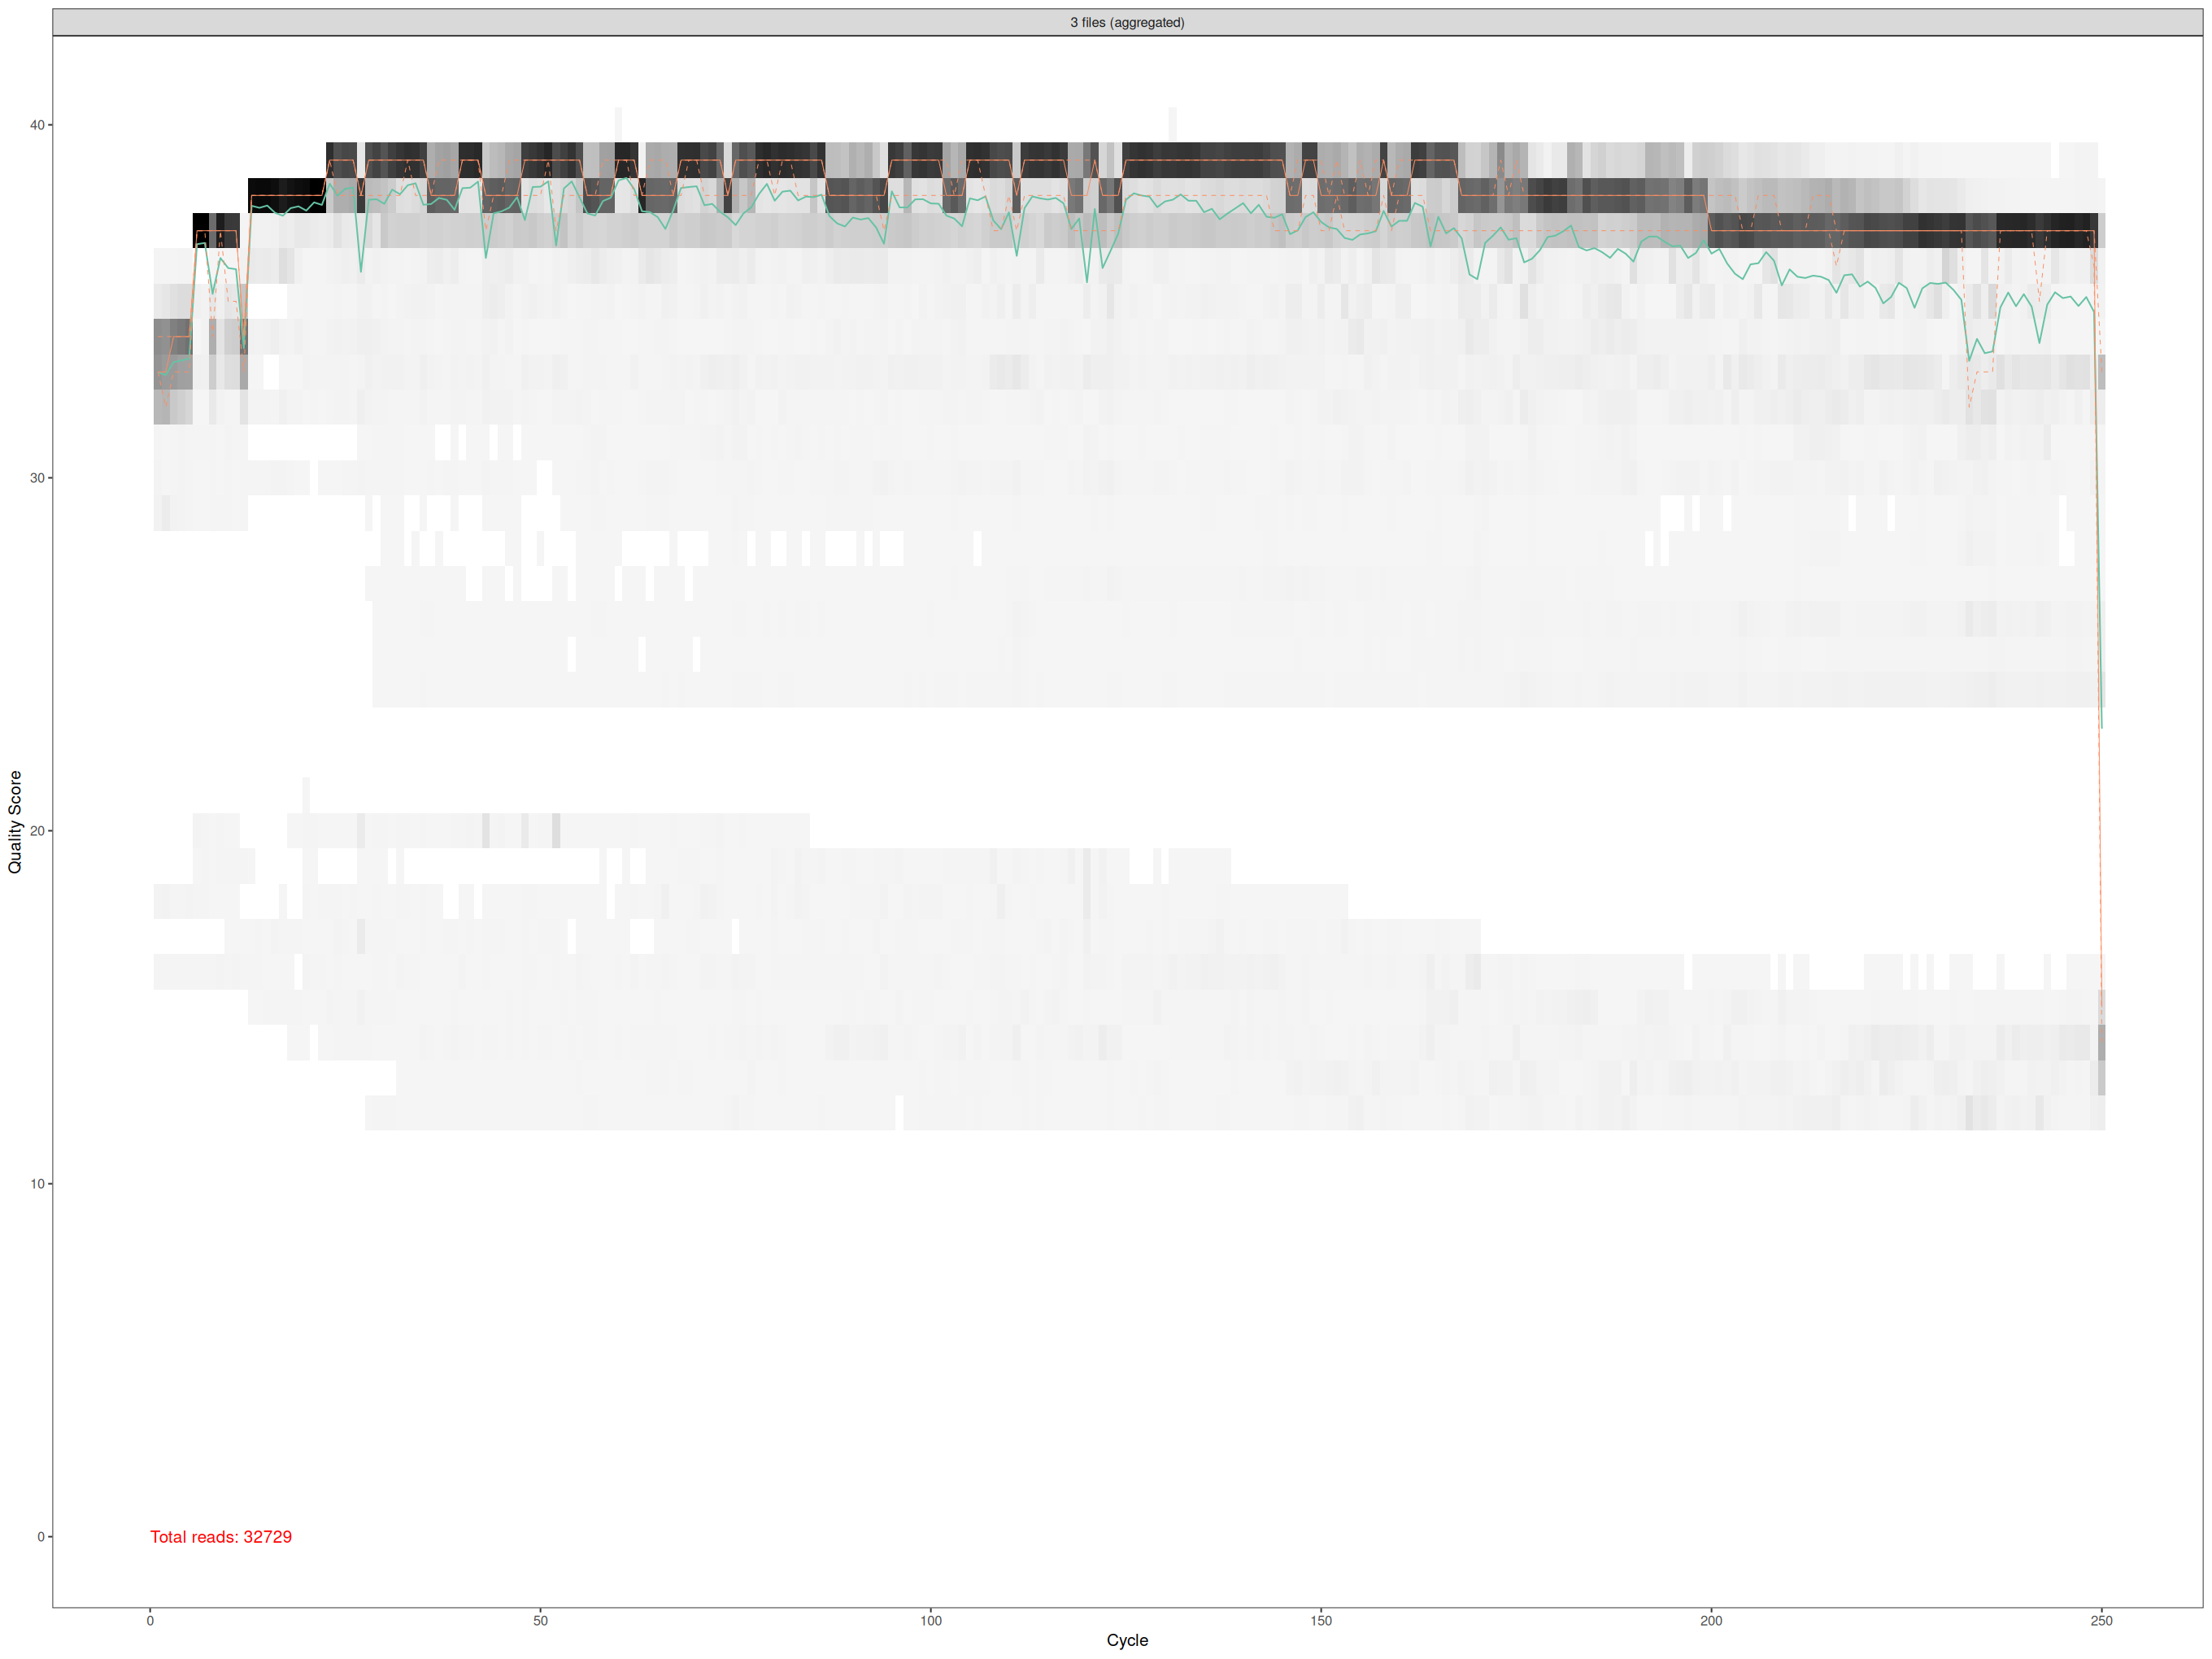

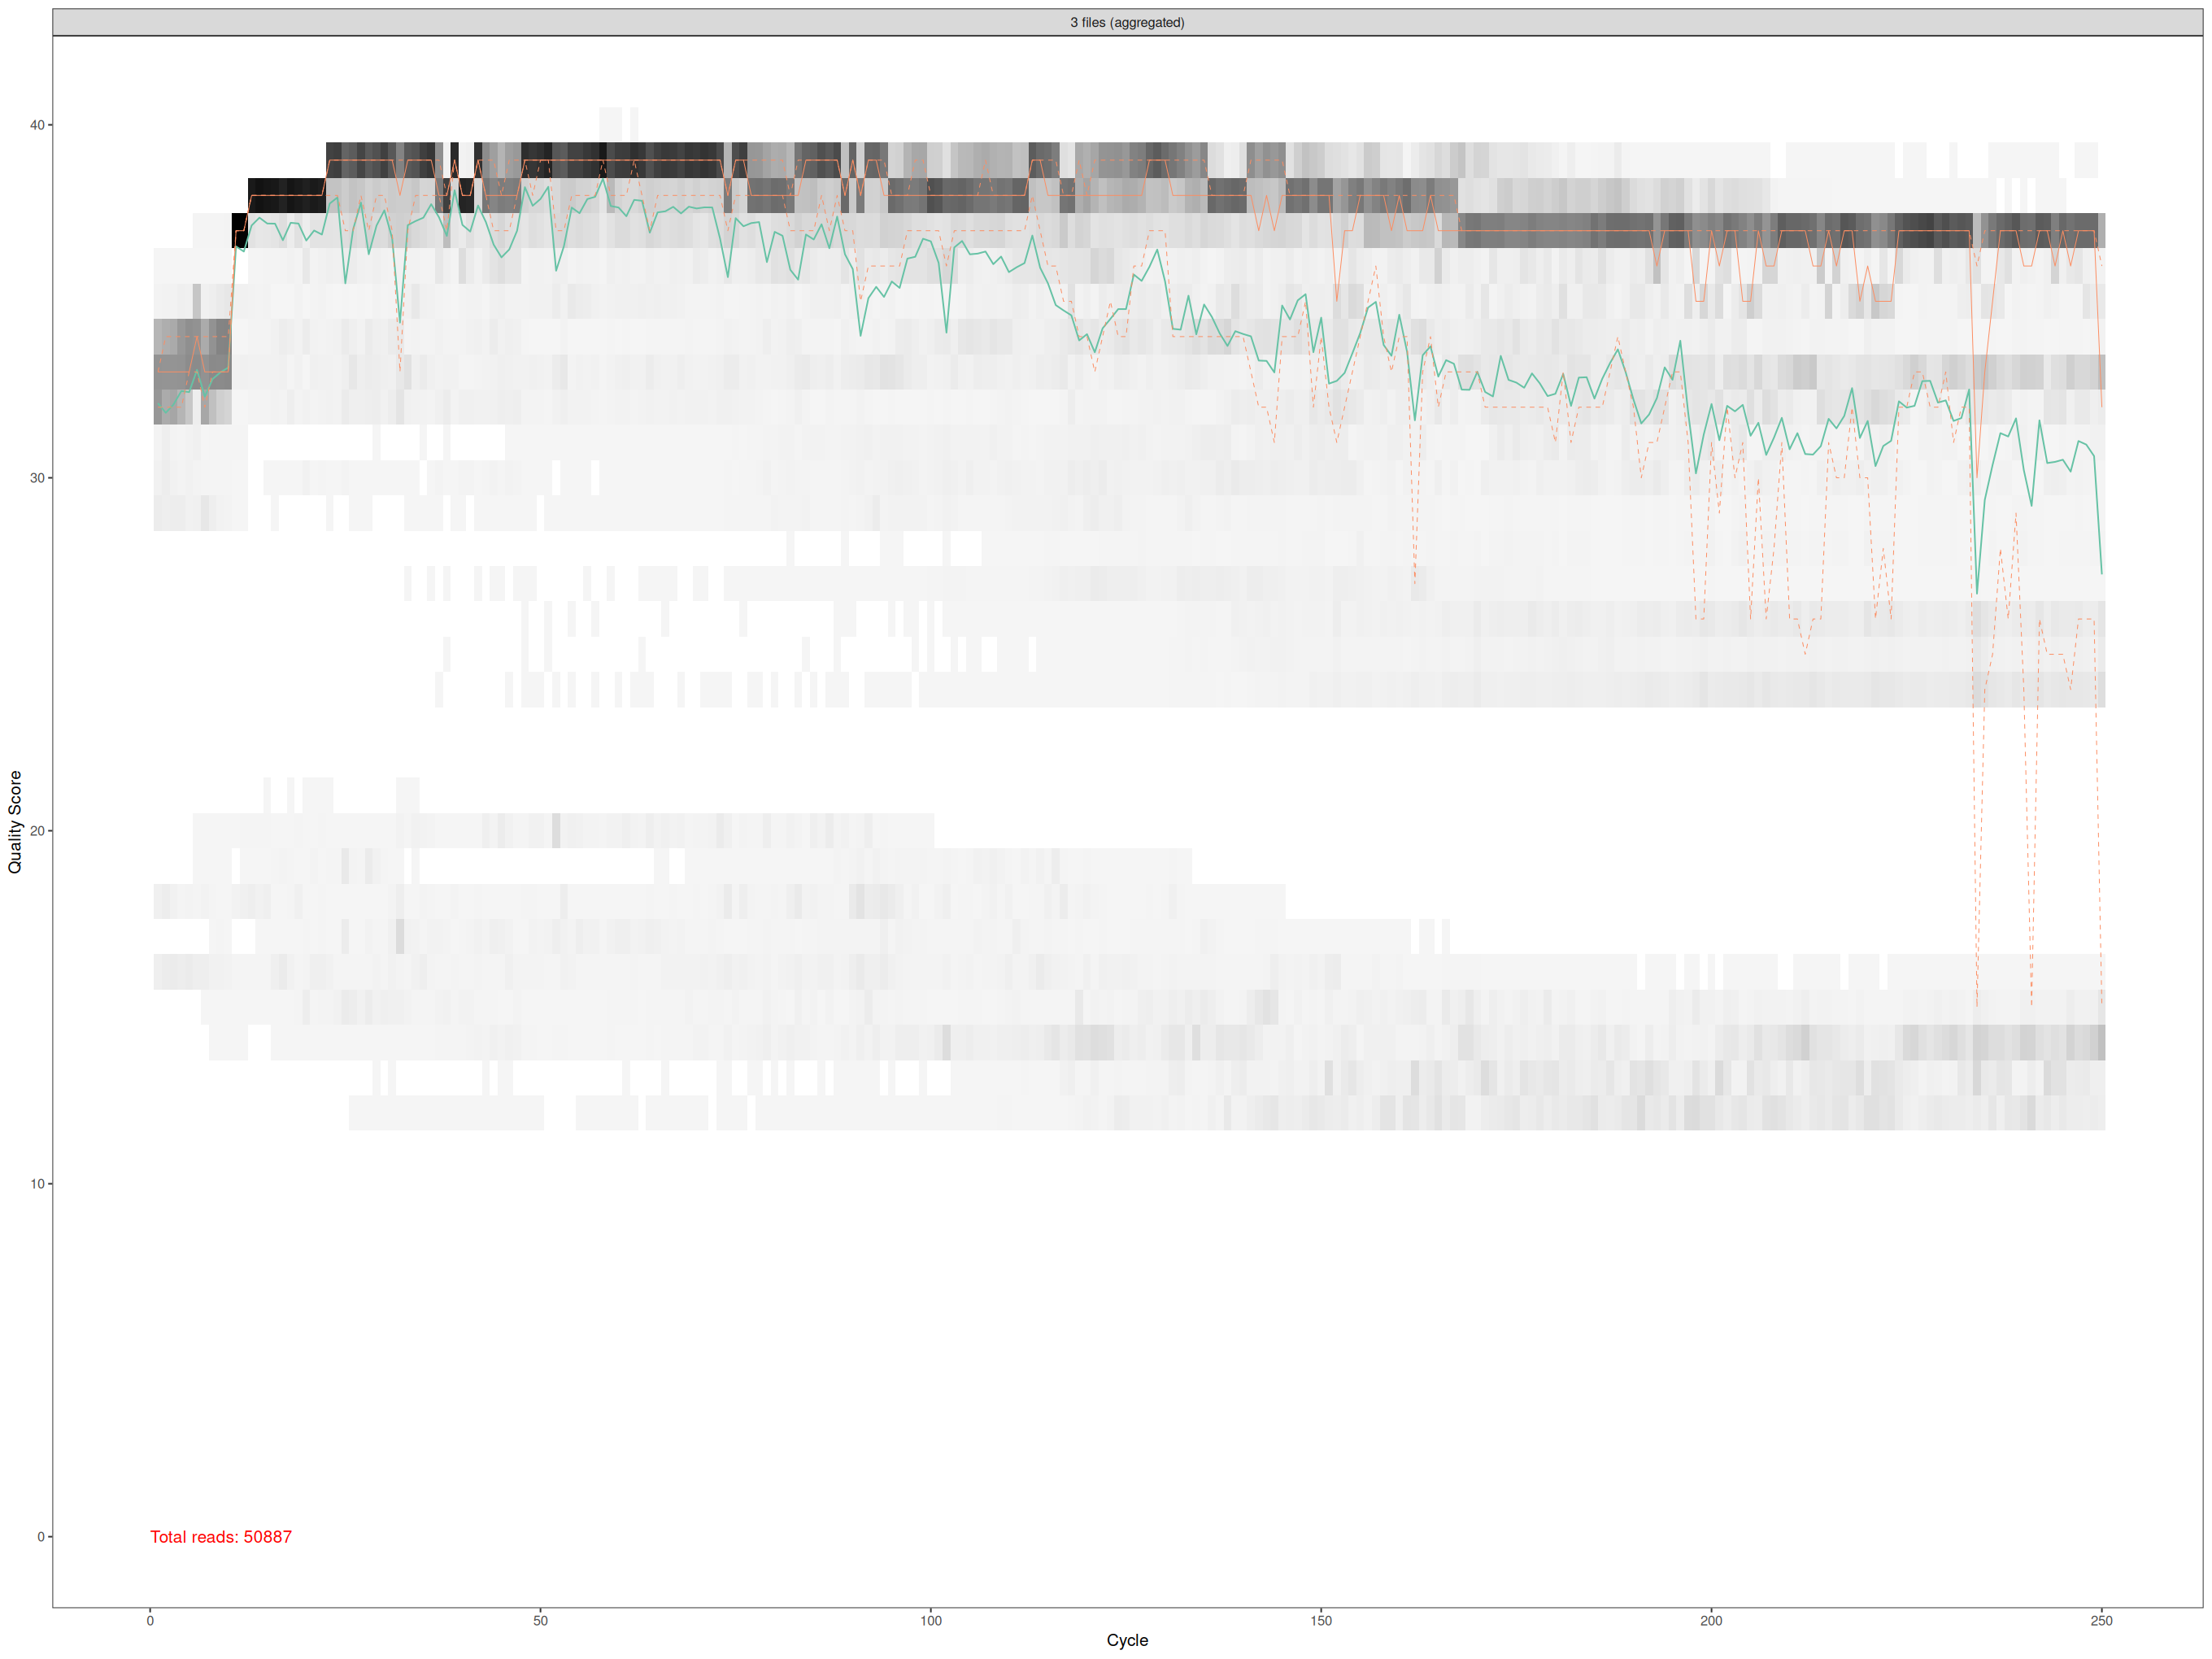

In [ ]:
plotQualityProfile(fnFs.16s[1:3], aggregate = TRUE)
plotQualityProfile(fnRs.ITS[1:3], aggregate = TRUE)
# THESE ARE TEST LINES, WE SHOULD GET AN IDEA OF WHERE THE READ SCORES DROP OFF FOR BOTH FWD AND RVR
# NOTE: the 1-/2-/3- prefixes are PLATES, not runs. All reads share one flowcell ID, so it's all 1 MiSeq run
#       -> error rates get learned once per locus (16S, ITS), not once per plate

### primer removal
Primers have to come off before denoising. Primer sequences contain ambiguous bases (e.g. `Y` = C or T), so the same primer shows up as several slightly different real sequences. dada2 would treat those differences as biological variation.

**16S: `trimLeft` in `filterAndTrim`**
- every 16S read starts with the primer, so we just chop off the first 19 (fwd) and 20 (rvr) bases
- the V4 amplicon is ~253 bp between the primers, longer than what's left of a 250 bp read after trimming. So reads never run past the end into the *other* primer, and nothing needs removing from the 3' end
- this is the approach in the main dada2 tutorial

**ITS: `cutadapt`** (following the dada2 ITS tutorial)
- ITS1 length varies a lot between fungi (roughly 100 to 300+ bp). For short ones, the read runs right through the amplicon into the reverse primer and adapter at the 3' end
- that position is different in every read, so a fixed `trimLeft` can't remove it. cutadapt *searches* each read for the primers and cuts them wherever they are
- cutadapt flags: `-g` fwd primer at the 5' end of R1, `-a` reverse complement of the rvr primer at the 3' end of R1, `-G`/`-A` the same for R2, `-n 2` remove up to 2 primers per read, `-m 1` drop reads that end up empty
- step 1: remove reads with any `N` first (`maxN = 0`), because Ns make primer matching unreliable

**check:** count primer hits in each orientation in one sample before and after removal. Before = lots of `Forward` hits (+ some `RevComp` for ITS), after = ~0 everywhere.

In [16]:
# ---- helper functions for primer checking (from the dada2 ITS tutorial) ----

# a primer can show up in reads in 4 orientations; return all 4 as text
allOrients <- function(primer) {
    dna <- DNAString(primer)
    orients <- c(Forward    = dna,
                 Complement = Biostrings::complement(dna),
                 Reverse    = Biostrings::reverse(dna),
                 RevComp    = Biostrings::reverseComplement(dna))
    return(sapply(orients, toString))
}

# number of reads in a fastq file that contain the primer (fixed = FALSE lets IUPAC codes like Y match C or T)
primerHits <- function(primer, fn) {
    nhits <- vcountPattern(primer, sread(readFastq(fn)), fixed = FALSE)
    return(sum(nhits > 0))
}

# table of primer hits: rows = primer x read direction, columns = orientation
countPrimers <- function(FWD, REV, fnF, fnR) {
    rbind(FWD.ForwardReads = sapply(allOrients(FWD), primerHits, fn = fnF),
          FWD.ReverseReads = sapply(allOrients(FWD), primerHits, fn = fnR),
          REV.ForwardReads = sapply(allOrients(REV), primerHits, fn = fnF),
          REV.ReverseReads = sapply(allOrients(REV), primerHits, fn = fnR))
}

# run cutadapt on each sample (paired), writing primer-free reads to outF/outR and appending output to a log file
runCutadapt <- function(fnF, fnR, outF, outR, FWD, REV, cutadapt, threads, logFile) {
    FWD.RC <- toString(reverseComplement(DNAString(FWD)))
    REV.RC <- toString(reverseComplement(DNAString(REV)))
    R1.flags <- c("-g", FWD, "-a", REV.RC)   # R1: fwd primer at start, rc of rvr primer if the read runs through
    R2.flags <- c("-G", REV, "-A", FWD.RC)   # R2: rvr primer at start, rc of fwd primer if the read runs through
    if (file.exists(logFile)) file.remove(logFile)
    for (i in seq_along(fnF)) {
        # shQuote() puts quotes around paths, needed because our folders have spaces in their names
        log <- system2(cutadapt,
                       args = c(R1.flags, R2.flags, "-n", 2, "-m", 1, "-j", threads,
                                "-o", shQuote(outF[i]), "-p", shQuote(outR[i]),
                                shQuote(fnF[i]), shQuote(fnR[i])),
                       stdout = TRUE, stderr = TRUE)
        cat(paste("=====", basename(fnF[i])), log, file = logFile, sep = "\n", append = TRUE)
    }
}

In [17]:
# ---- 16S: just check that the primers are where we expect (start of each read). trimLeft removes them during filter & trim
countPrimers(FWD.16s, REV.16s, fnFs.16s[1], fnRs.16s[1])
# expect: FWD.ForwardReads/Forward and REV.ReverseReads/Forward = most reads, ~0 in the RevComp columns (no read-through)

                 Forward Complement Reverse RevComp
FWD.ForwardReads    3164          0       0       0
FWD.ReverseReads       0          0       0       0
REV.ForwardReads       0          0       0       0
REV.ReverseReads   10768          0       0       0

In [18]:
# ---- ITS step 1: remove reads containing Ns (only so that primer matching works; the real filtering comes later)
filtNPath.ITS <- file.path(procPath, "ITS", "filtN")
fnFs.filtN.ITS <- file.path(filtNPath.ITS, paste0(sample.names.ITS, "_F_filtN.fastq.gz"))
fnRs.filtN.ITS <- file.path(filtNPath.ITS, paste0(sample.names.ITS, "_R_filtN.fastq.gz"))

filtN.ITS <- filterAndTrim(fnFs.ITS, fnFs.filtN.ITS, fnRs.ITS, fnRs.filtN.ITS,
                           maxN = 0, multithread = nThreads)

# save the read counts (the tracking table needs them; lets you resume later without redoing this)
write.csv(filtN.ITS, file.path(procPath, "ITS", "filtNSummary_ITS.csv"))

# ---- ITS step 2: primer hits BEFORE cutadapt
countPrimers(FWD.ITS, REV.ITS, fnFs.filtN.ITS[1], fnRs.filtN.ITS[1])

                 Forward Complement Reverse RevComp
FWD.ForwardReads   18906          0       0       0
FWD.ReverseReads       0          0       0       0
REV.ForwardReads       0          0       0       0
REV.ReverseReads   19159          0       0       0

In [13]:
# ---- ITS step 3: run cutadapt (slow-ish: ~190 samples, one at a time)
# samples where every read had an N have no filtN file, so only run cutadapt on files that exist
hasFiltN.ITS <- file.exists(fnFs.filtN.ITS) & file.exists(fnRs.filtN.ITS)
sample.names.ITS[!hasFiltN.ITS]   # samples lost at this step (hopefully none)

cutPath.ITS <- file.path(procPath, "ITS", "cutadapt")
dir.create(cutPath.ITS, recursive = TRUE, showWarnings = FALSE)
fnFs.cut.ITS <- file.path(cutPath.ITS, paste0(sample.names.ITS, "_F_cut.fastq.gz"))
fnRs.cut.ITS <- file.path(cutPath.ITS, paste0(sample.names.ITS, "_R_cut.fastq.gz"))

runCutadapt(fnFs.filtN.ITS[hasFiltN.ITS], fnRs.filtN.ITS[hasFiltN.ITS],
            fnFs.cut.ITS[hasFiltN.ITS],   fnRs.cut.ITS[hasFiltN.ITS],
            FWD.ITS, REV.ITS, cutadaptPath, nThreads,
            logFile = file.path(procPath, "ITS", "cutadapt_log.txt"))

# ---- ITS step 4: primer hits AFTER cutadapt, should be ~0 everywhere
countPrimers(FWD.ITS, REV.ITS, fnFs.cut.ITS[1], fnRs.cut.ITS[1])

                 Forward Complement Reverse RevComp
FWD.ForwardReads       0          0       0       0
FWD.ReverseReads       0          0       0       0
REV.ForwardReads       0          0       0       0
REV.ReverseReads       0          0       0       0

### filter & trim
- Here the workflow splits between 16s & ITS
- As per DADA2 tutorial, we should NOT truncate ITS samples to a fixed length due to indel variation
    - Therefore, ITS data will NOT use trunclen()
    - instead `minLen` drops tiny leftover reads
- what each setting does (values are in the parameter cell):
    - `truncLen` (16S only): cut reads at a fixed length, before quality crashes at the end of the read. The forward and reverse reads must still overlap enough to merge later
    - `trimLeft` (16S only): cut the primer off the start of each read
    - `maxEE`: **expected errors** = sum of the error probabilities of every base in the read (from the quality scores). `maxEE = 2` means "drop reads that probably contain more than 2 errors". This is better than an average quality cutoff, because one terrible base counts properly
    - `truncQ = 2`: cut the read at the first base with quality 2 (Illumina's "this base is junk" flag)
    - `maxN = 0`: dada2 can't handle Ns, so reads with any N are removed
    - `rm.phix = TRUE`: remove reads from the PhiX control genome Illumina spikes into runs
- a sample that loses ALL its reads gets no output file, so those samples are dropped at the end of this section

In [19]:
# 16s
filtPath.16s <- file.path(procPath, "16S", "filtered")
filtFs.16s <- file.path(filtPath.16s, paste0(sample.names.16s, "_F_filt.fastq.gz"))
filtRs.16s <- file.path(filtPath.16s, paste0(sample.names.16s, "_R_filt.fastq.gz"))
names(filtFs.16s) <- sample.names.16s
names(filtRs.16s) <- sample.names.16s

filtOut.16s <- filterAndTrim(fnFs.16s, filtFs.16s, fnRs.16s, filtRs.16s,
                             trimLeft = c(nchar(FWD.16s), nchar(REV.16s)),   # remove primers (19, 20 bp)
                             truncLen = truncLen.16s,
                             maxN = 0, maxEE = maxEE.16s, truncQ = truncQ,
                             rm.phix = TRUE, compress = TRUE, multithread = nThreads)


# ITS (input = cutadapt output, no truncLen)
filtPath.ITS <- file.path(procPath, "ITS", "filtered")
filtFs.ITS <- file.path(filtPath.ITS, paste0(sample.names.ITS, "_F_filt.fastq.gz"))
filtRs.ITS <- file.path(filtPath.ITS, paste0(sample.names.ITS, "_R_filt.fastq.gz"))
names(filtFs.ITS) <- sample.names.ITS
names(filtRs.ITS) <- sample.names.ITS

hasCut.ITS <- file.exists(fnFs.cut.ITS) & file.exists(fnRs.cut.ITS)
filtOut.ITS <- filterAndTrim(fnFs.cut.ITS[hasCut.ITS], filtFs.ITS[hasCut.ITS],
                             fnRs.cut.ITS[hasCut.ITS], filtRs.ITS[hasCut.ITS],
                             minLen = minLen.ITS,
                             maxN = 0, maxEE = maxEE.ITS, truncQ = truncQ,
                             rm.phix = TRUE, compress = TRUE, multithread = nThreads)

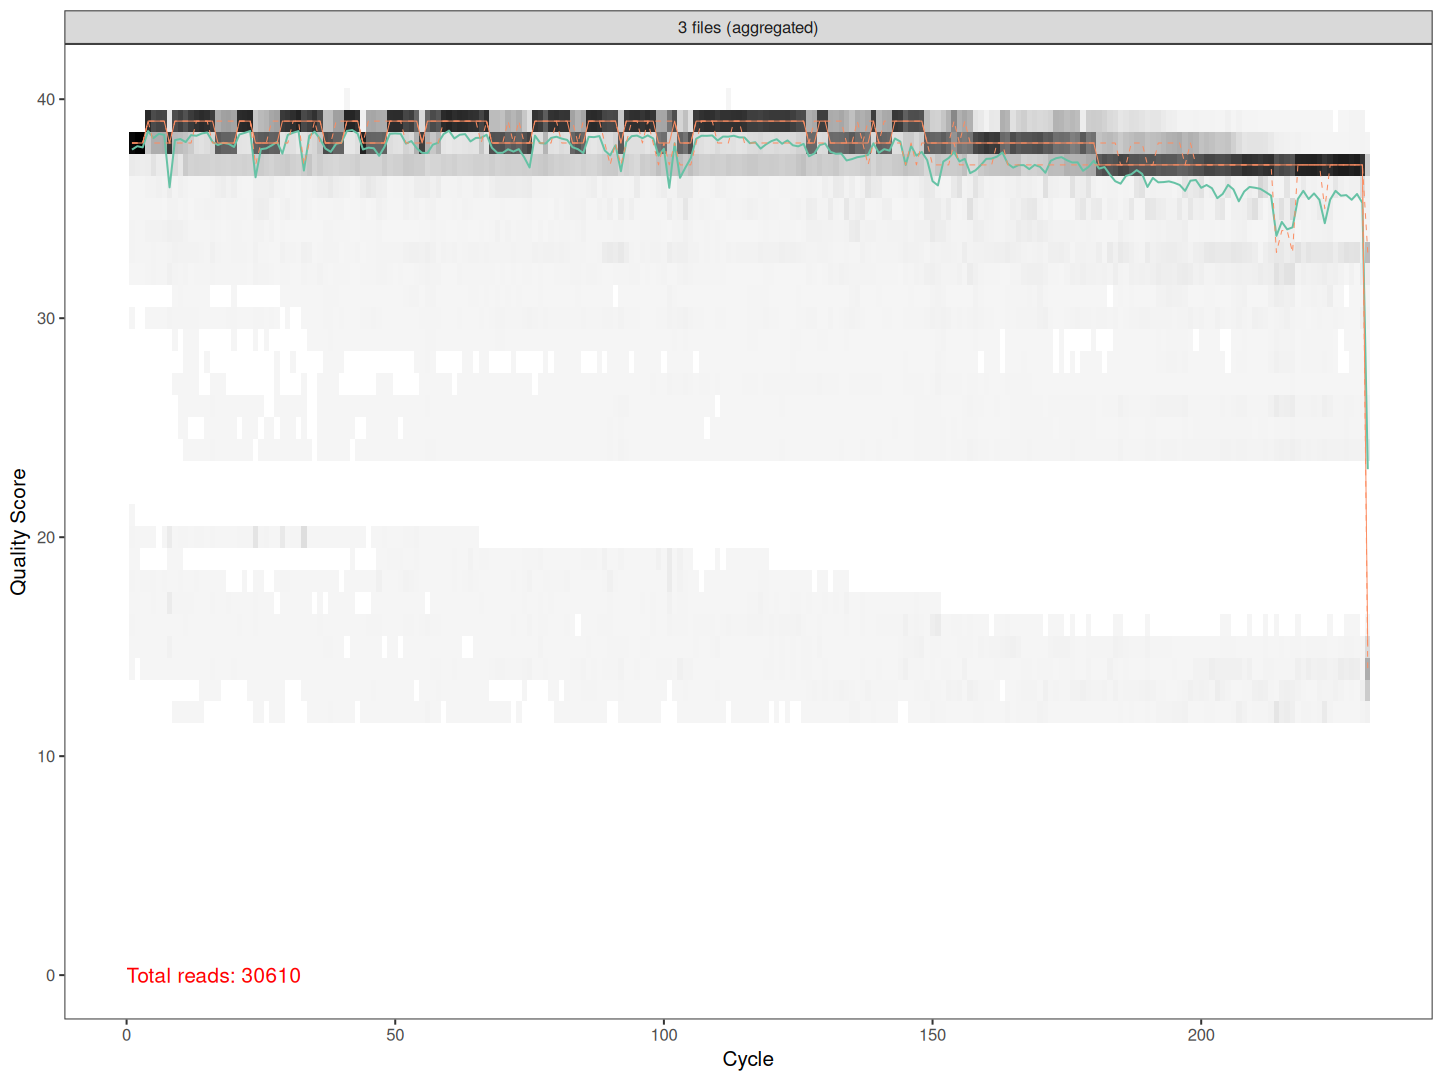

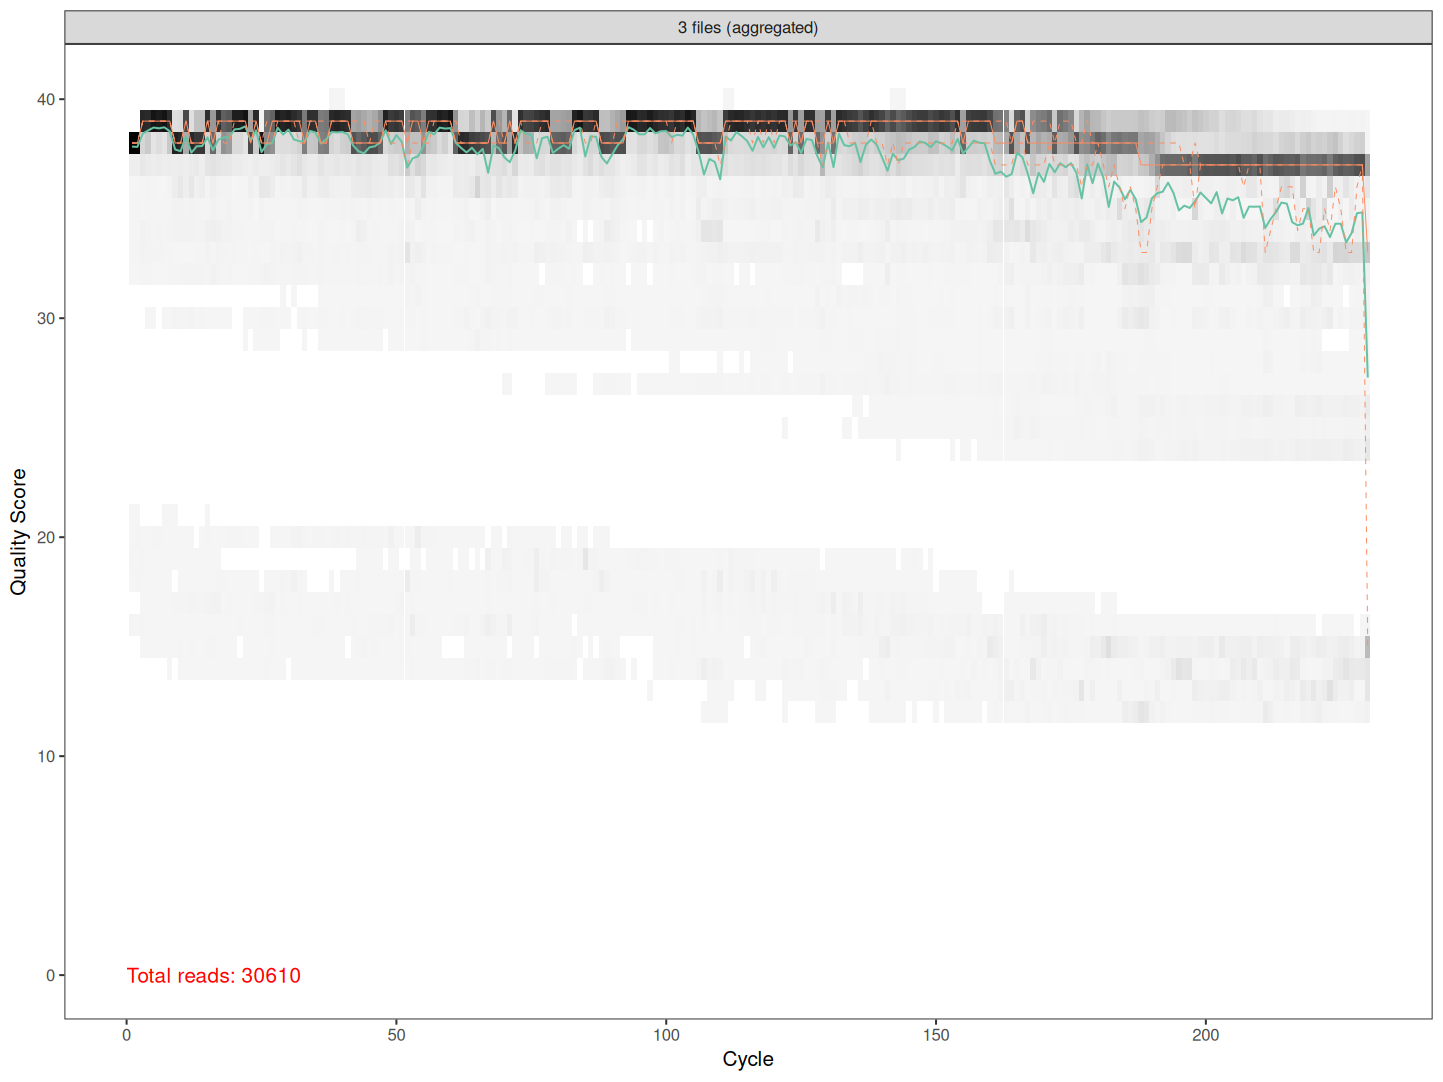

In [20]:
# how many reads went in & came out of filtering, per sample
head(filtOut.16s)
head(filtOut.ITS)
summary(filtOut.16s[, "reads.out"] / filtOut.16s[, "reads.in"])   # fraction of reads kept per sample
summary(filtOut.ITS[, "reads.out"] / filtOut.ITS[, "reads.in"])

write.csv(filtOut.16s, file.path(procPath, "16S", "filterSummary_16S.csv"))
write.csv(filtOut.ITS, file.path(procPath, "ITS",  "filterSummary_ITS.csv"))

# drop samples with no reads left (no output file was written for them)
keep.16s <- file.exists(filtFs.16s) & file.exists(filtRs.16s)
keep.ITS <- file.exists(filtFs.ITS) & file.exists(filtRs.ITS)
sample.names.16s[!keep.16s]   # dropped 16S samples
sample.names.ITS[!keep.ITS]   # dropped ITS samples

filtFs.16s <- filtFs.16s[keep.16s]
filtRs.16s <- filtRs.16s[keep.16s]
filtFs.ITS <- filtFs.ITS[keep.ITS]
filtRs.ITS <- filtRs.ITS[keep.ITS]

# quick look at a few filtered samples: quality should now stay high to the end of each read
plotQualityProfile(filtFs.16s[1:3], aggregate = TRUE)
plotQualityProfile(filtRs.16s[1:3], aggregate = TRUE)

### learn error rates
- dada2's core idea: for every unique sequence, ask "is this a real biological variant, or an error-ridden copy of a more common sequence?" To answer that, it needs to know how often each substitution (A->C, A->G, ...) happens at each quality score **in this run**
- `learnErrors` estimates that from the data itself. It alternates between denoising a subset of reads and re-estimating error rates until they stop changing
- error rates differ between sequencing runs, so they're learned once **per run**. This is all one run, so once per locus and per read direction (fwd/rvr reads have different error profiles)
- `nbases = 1e8` (default) = use enough samples to reach 100 million bases. `randomize = TRUE` picks those samples at random rather than taking the first files alphabetically (which would be all plate 1)
- **check `plotErrors`:** points are observed error rates, the black line is the fitted model, and the red line is what the quality scores alone would predict. The black line should follow the points, and error rates should fall as quality rises
- (MiSeq gives the full range of quality scores, so this doesn't need the NovaSeq "binned quality" workaround)

In [21]:
# 16s
errF.16s <- learnErrors(filtFs.16s, nbases = nbasesLearn, randomize = TRUE, multithread = nThreads)
errR.16s <- learnErrors(filtRs.16s, nbases = nbasesLearn, randomize = TRUE, multithread = nThreads)

# ITS
errF.ITS <- learnErrors(filtFs.ITS, nbases = nbasesLearn, randomize = TRUE, multithread = nThreads)
errR.ITS <- learnErrors(filtRs.ITS, nbases = nbasesLearn, randomize = TRUE, multithread = nThreads)

# save, so you don't have to re-learn them if R restarts
saveRDS(list(errF = errF.16s, errR = errR.16s), file.path(procPath, "16S", "errorRates_16S.rds"))
saveRDS(list(errF = errF.ITS, errR = errR.ITS), file.path(procPath, "ITS", "errorRates_ITS.rds"))

100405998 total bases in 434658 reads from 39 samples will be used for learning the error rates.
100974830 total bases in 439021 reads from 39 samples will be used for learning the error rates.
100023401 total bases in 438021 reads from 43 samples will be used for learning the error rates.
102493024 total bases in 448637 reads from 40 samples will be used for learning the error rates.


Warning messages:
1: In scale_y_log10() :
  log-10 transformation introduced infinite values.
2: In scale_y_log10() :
  log-10 transformation introduced infinite values.


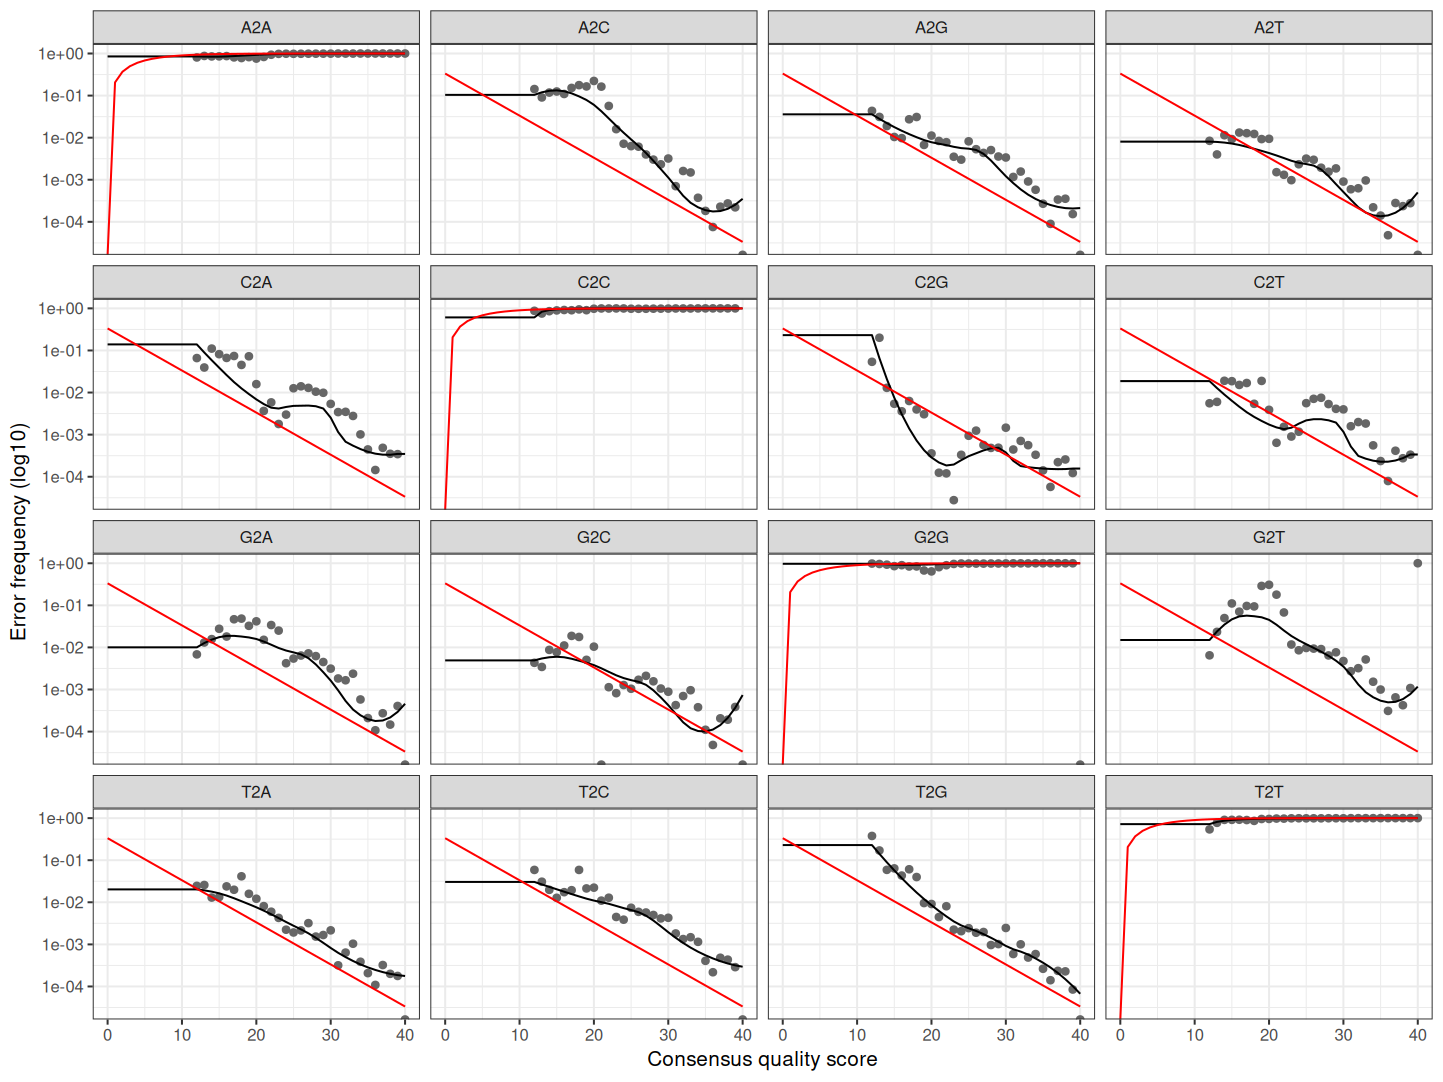

Warning messages:
1: In scale_y_log10() :
  log-10 transformation introduced infinite values.
2: In scale_y_log10() :
  log-10 transformation introduced infinite values.


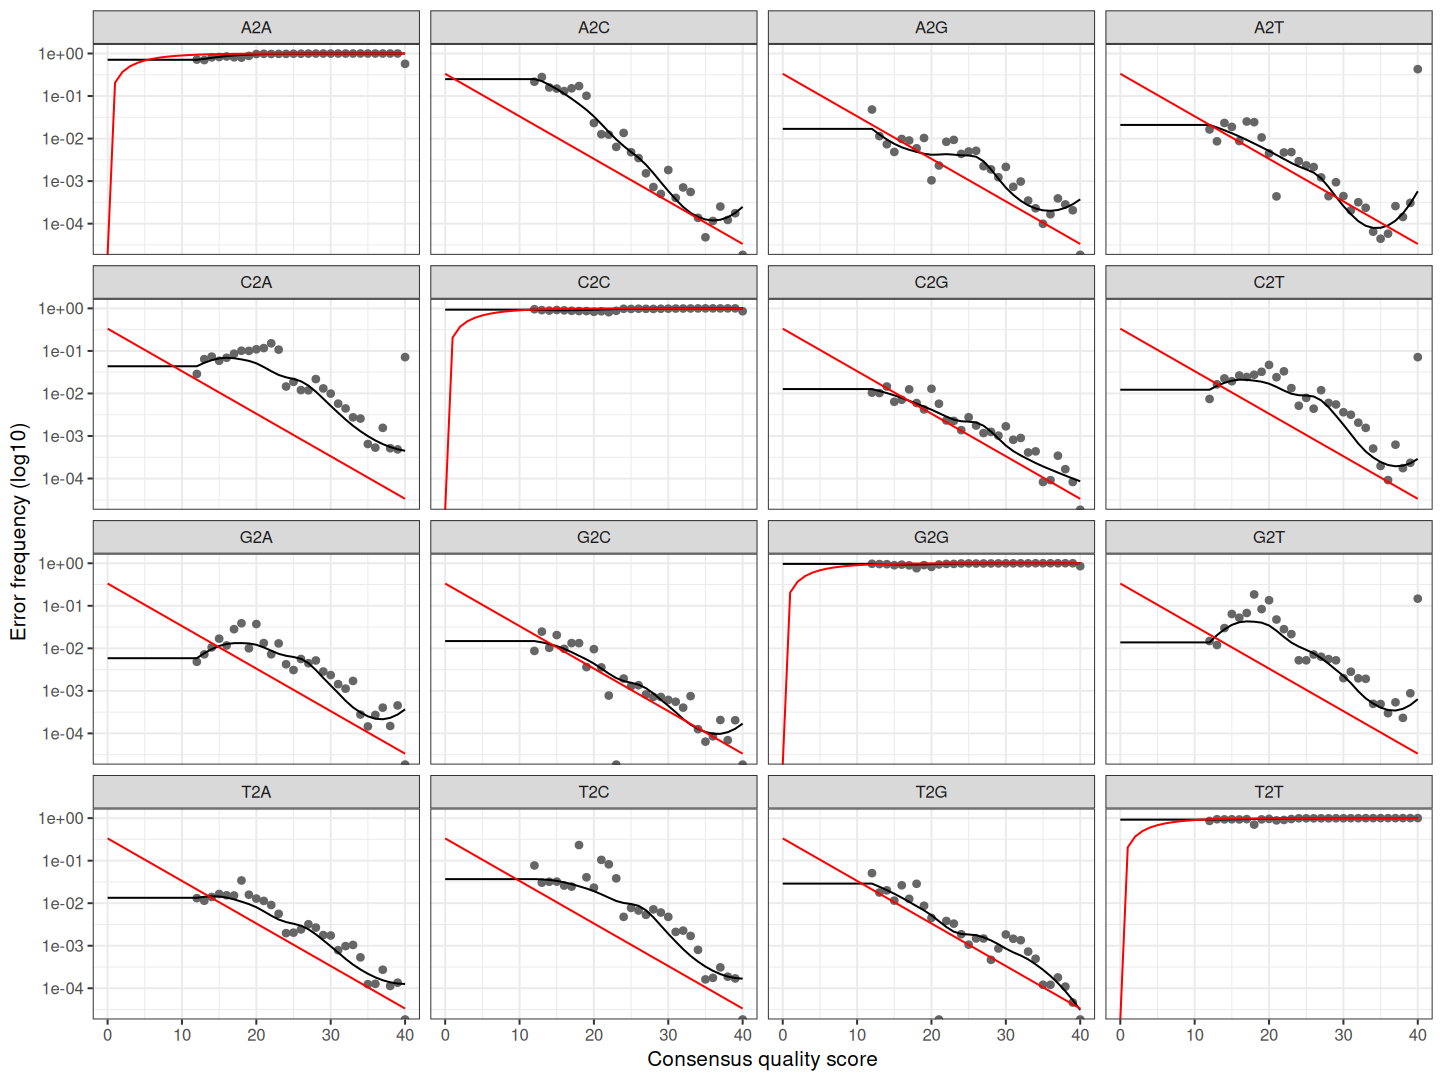

Warning messages:
1: In scale_y_log10() :
  log-10 transformation introduced infinite values.
2: In scale_y_log10() :
  log-10 transformation introduced infinite values.


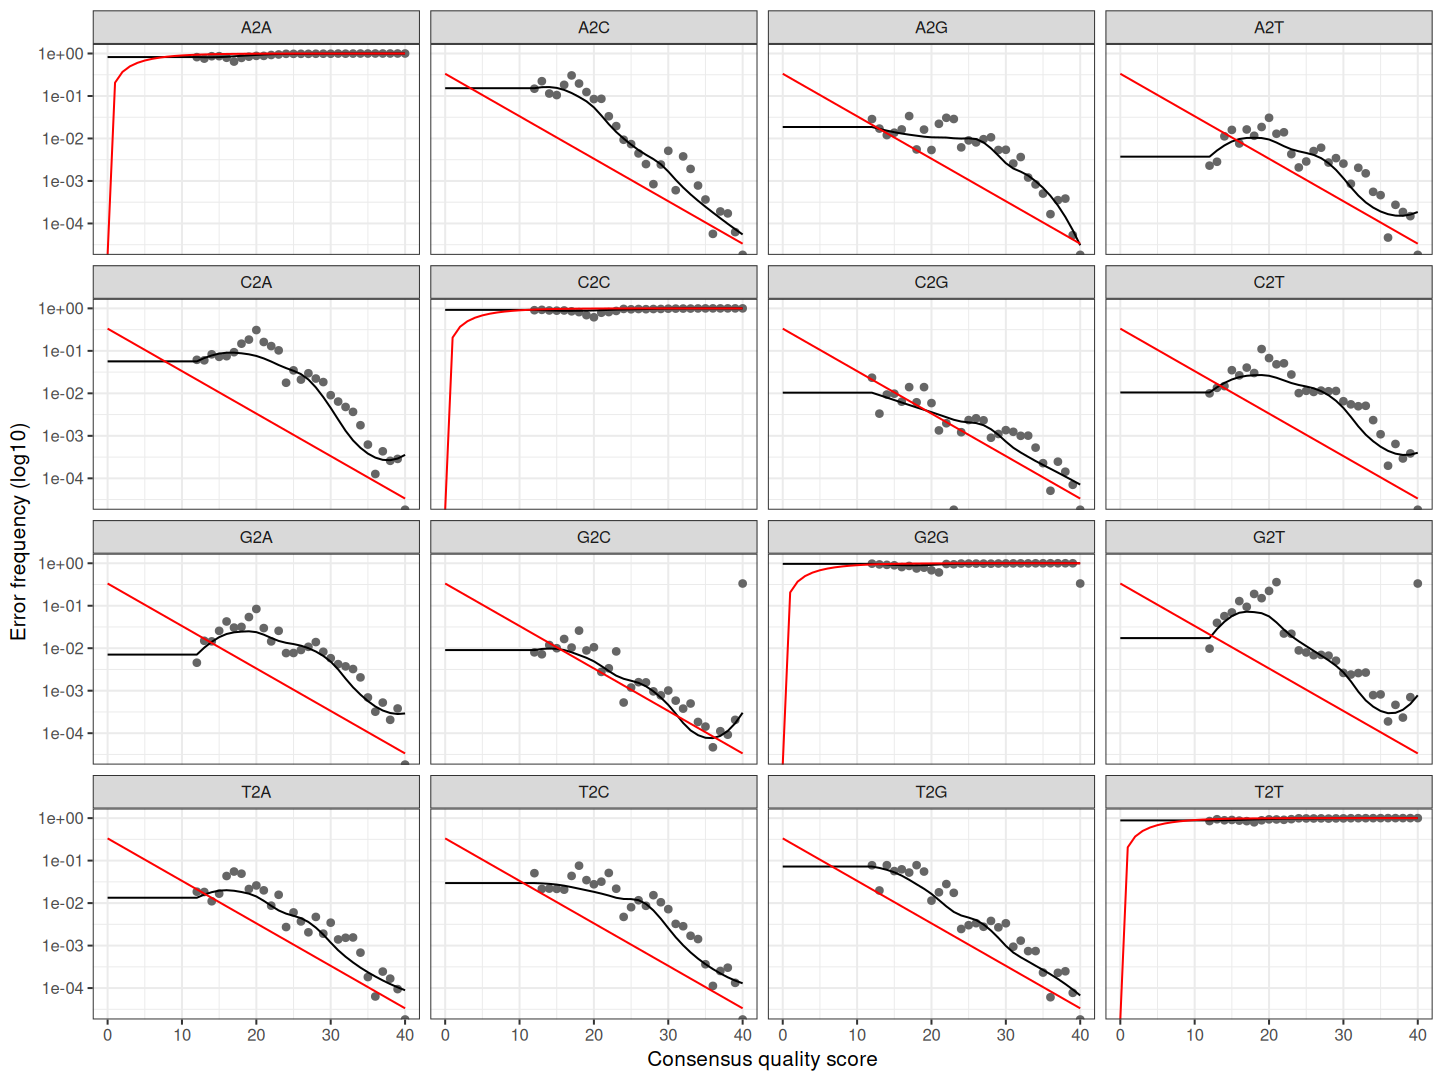

Warning messages:
1: In scale_y_log10() :
  log-10 transformation introduced infinite values.
2: In scale_y_log10() :
  log-10 transformation introduced infinite values.


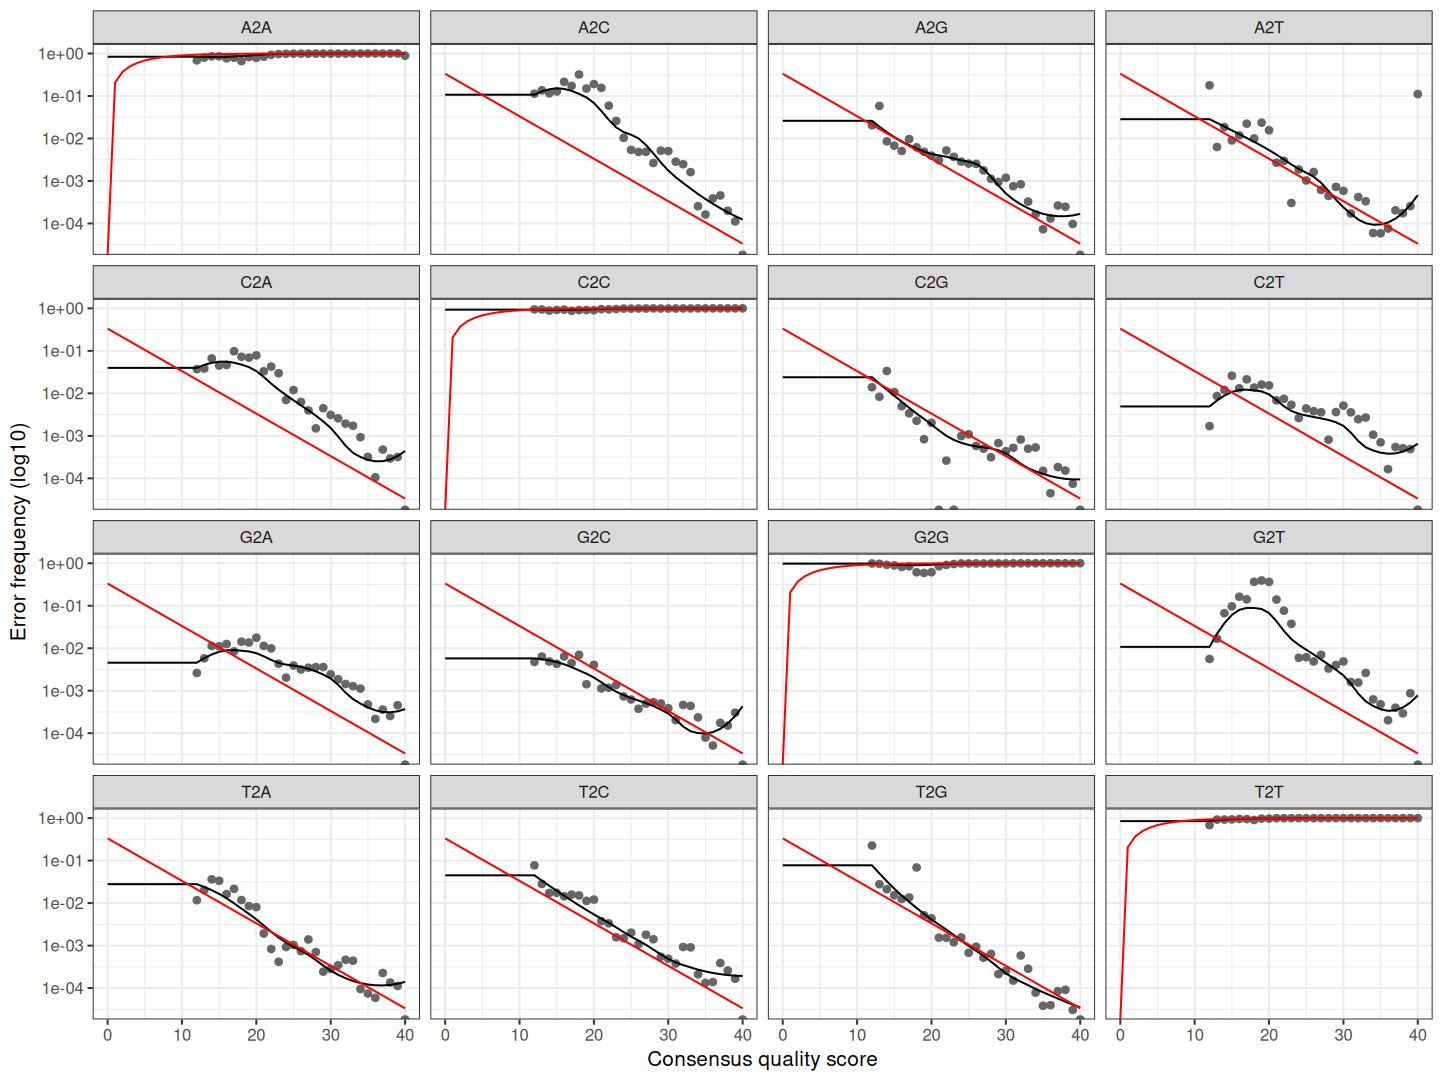

In [22]:
plotErrors(errF.16s, nominalQ = TRUE)
plotErrors(errR.16s, nominalQ = TRUE)
plotErrors(errF.ITS, nominalQ = TRUE)
plotErrors(errR.ITS, nominalQ = TRUE)

### denoise (sample inference)
- `dada()` uses the error model to split each sample's reads into **ASVs** (amplicon sequence variants: exact sequences, down to 1 bp differences), instead of clustering at 97% into OTUs like the paper's older pipeline
- **pooling** (`poolMethod` in the parameter cell):
    - `pool = FALSE`: each sample is denoised on its own. Fast, but a variant that is rare in every sample (e.g. 1-2 reads per sample) can be thrown out as an error every time, even if it appears in many samples
    - `pool = TRUE`: all samples together. Most sensitive to rare variants, but slow and memory hungry
    - `pool = "pseudo"`: samples are processed one by one twice. Variants found in the 1st pass are used as "priors" in the 2nd, so a rare variant seen in other samples gets a fair chance. Close to `TRUE` in sensitivity, much cheaper
    - **picked `"pseudo"`** because this paper is literally about *rare* microbes. Expect it to take a while (16S has ~2.7 GB of reads, so maybe an hour or more)
- forward and reverse reads are denoised separately and then merged

In [5]:
# 16s
dadaFs.16s <- dada(filtFs.16s, err = errF.16s, pool = poolMethod, multithread = nThreads)
dadaRs.16s <- dada(filtRs.16s, err = errR.16s, pool = poolMethod, multithread = nThreads)

# ITS
dadaFs.ITS <- dada(filtFs.ITS, err = errF.ITS, pool = poolMethod, multithread = nThreads)
dadaRs.ITS <- dada(filtRs.ITS, err = errR.ITS, pool = poolMethod, multithread = nThreads)

# save, so merging (and everything after) can be rerun without redoing this slow step
saveRDS(list(dadaFs = dadaFs.16s, dadaRs = dadaRs.16s), file.path(procPath, "16S", "dada_16S.rds"))
saveRDS(list(dadaFs = dadaFs.ITS, dadaRs = dadaRs.ITS), file.path(procPath, "ITS", "dada_ITS.rds"))

dadaFs.16s[[1]]   # summary for one sample: how many ASVs from how many unique sequences
dadaFs.ITS[[1]]

Sample 1 - 10586 reads in 1798 unique sequences.
Sample 2 - 12122 reads in 966 unique sequences.
Sample 3 - 7902 reads in 893 unique sequences.
Sample 4 - 12070 reads in 1001 unique sequences.
Sample 5 - 11729 reads in 932 unique sequences.
Sample 6 - 7260 reads in 742 unique sequences.
Sample 7 - 11363 reads in 979 unique sequences.
Sample 8 - 9783 reads in 959 unique sequences.
Sample 9 - 10902 reads in 902 unique sequences.
Sample 10 - 4384 reads in 676 unique sequences.
Sample 11 - 8607 reads in 762 unique sequences.
Sample 12 - 10659 reads in 922 unique sequences.
Sample 13 - 35954 reads in 5346 unique sequences.
Sample 14 - 11117 reads in 876 unique sequences.
Sample 15 - 13861 reads in 1399 unique sequences.
Sample 16 - 11682 reads in 796 unique sequences.
Sample 17 - 14435 reads in 1088 unique sequences.
Sample 18 - 13791 reads in 1412 unique sequences.
Sample 19 - 15743 reads in 1342 unique sequences.
Sample 20 - 8926 reads in 745 unique sequences.
Sample 21 - 18158 reads in 1

dada-class: object describing DADA2 denoising results
16 sequence variants were inferred from 1481 input unique sequences.
Key parameters: OMEGA_A = 1e-40, OMEGA_C = 1e-40, BAND_SIZE = 16

### resume point: start here after an R restart (merge step onward)
To rerun from **merge paired reads** onward without redoing filtering / error learning / denoising:
1. run the **parameter cell** and the **library cell** at the top
2. run the cell below. It rebuilds every variable the later steps need, from files saved earlier:
    - `data/processed/sampleData_*.csv`: sample tables + sample names
    - `filterSummary_*.csv`, `filtNSummary_ITS.csv`: read counts for the tracking table
    - `filtered/`, `cutadapt/` folders: filtered-file paths, and which samples survived
    - `errorRates_*.rds`, `dada_*.rds`: error models + denoised reads
3. continue with the merge cell

`dada_*.rds` only exists after the denoise cell has run **with the new `saveRDS` lines**. If it's missing, the cell stops and tells you.

If you're running the whole notebook top to bottom, **skip** this cell.

In [6]:
# ==== RESUME FROM THE MERGE STEP (run the parameter + library cells first) ====

# ---- sample tables & sample names (same order as the fastq files) ----
sampData.16s <- read.csv(file.path(procPath, "sampleData_16S.csv"))
sampData.ITS <- read.csv(file.path(procPath, "sampleData_ITS.csv"))
rownames(sampData.16s) <- sampData.16s$sampleID
rownames(sampData.ITS) <- sampData.ITS$sampleID
sample.names.16s <- sampData.16s$sampleID
sample.names.ITS <- sampData.ITS$sampleID

# ---- filtered fastq paths (same names as in the filter & trim cell), minus samples that lost all reads ----
filtPath.16s <- file.path(procPath, "16S", "filtered")
filtFs.16s <- file.path(filtPath.16s, paste0(sample.names.16s, "_F_filt.fastq.gz"))
filtRs.16s <- file.path(filtPath.16s, paste0(sample.names.16s, "_R_filt.fastq.gz"))
names(filtFs.16s) <- sample.names.16s
names(filtRs.16s) <- sample.names.16s
keep.16s <- file.exists(filtFs.16s) & file.exists(filtRs.16s)
filtFs.16s <- filtFs.16s[keep.16s]
filtRs.16s <- filtRs.16s[keep.16s]

filtPath.ITS <- file.path(procPath, "ITS", "filtered")
filtFs.ITS <- file.path(filtPath.ITS, paste0(sample.names.ITS, "_F_filt.fastq.gz"))
filtRs.ITS <- file.path(filtPath.ITS, paste0(sample.names.ITS, "_R_filt.fastq.gz"))
names(filtFs.ITS) <- sample.names.ITS
names(filtRs.ITS) <- sample.names.ITS
keep.ITS <- file.exists(filtFs.ITS) & file.exists(filtRs.ITS)
filtFs.ITS <- filtFs.ITS[keep.ITS]
filtRs.ITS <- filtRs.ITS[keep.ITS]

# which ITS samples made it through cutadapt (the tracking table needs this)
cutPath.ITS <- file.path(procPath, "ITS", "cutadapt")
fnFs.cut.ITS <- file.path(cutPath.ITS, paste0(sample.names.ITS, "_F_cut.fastq.gz"))
fnRs.cut.ITS <- file.path(cutPath.ITS, paste0(sample.names.ITS, "_R_cut.fastq.gz"))
hasCut.ITS <- file.exists(fnFs.cut.ITS) & file.exists(fnRs.cut.ITS)

# ---- read counts from filtering (for the tracking table) ----
filtOut.16s <- as.matrix(read.csv(file.path(procPath, "16S", "filterSummary_16S.csv"), row.names = 1))
filtOut.ITS <- as.matrix(read.csv(file.path(procPath, "ITS", "filterSummary_ITS.csv"), row.names = 1))
stopifnot(nrow(filtOut.16s) == length(sample.names.16s))   # one row per 16S sample
stopifnot(nrow(filtOut.ITS) == sum(hasCut.ITS))            # one row per ITS sample that went through cutadapt

# ITS N-removal counts: read the saved file if it exists; otherwise count reads in the fastq files once and save them
filtNFile.ITS <- file.path(procPath, "ITS", "filtNSummary_ITS.csv")
if (file.exists(filtNFile.ITS)) {
    filtN.ITS <- as.matrix(read.csv(filtNFile.ITS, row.names = 1))
} else {
    fnFs.ITS <- sort(list.files(seqPath.ITS, pattern = "_R1_001.fastq", full.names = TRUE))
    fnFs.filtN.ITS <- file.path(procPath, "ITS", "filtN", paste0(sample.names.ITS, "_F_filtN.fastq.gz"))
    readsIn  <- countFastq(fnFs.ITS)$records                       # reads in each raw file
    readsOut <- rep(0, length(fnFs.filtN.ITS))                     # reads left after N removal (0 if no file)
    hasFiltN <- file.exists(fnFs.filtN.ITS)
    readsOut[hasFiltN] <- countFastq(fnFs.filtN.ITS[hasFiltN])$records
    filtN.ITS <- cbind(reads.in = readsIn, reads.out = readsOut)
    rownames(filtN.ITS) <- basename(fnFs.ITS)
    write.csv(filtN.ITS, filtNFile.ITS)
}
stopifnot(nrow(filtN.ITS) == length(sample.names.ITS))

# ---- error models (not needed to merge, but handy for plotErrors) ----
err.16s <- readRDS(file.path(procPath, "16S", "errorRates_16S.rds"))
err.ITS <- readRDS(file.path(procPath, "ITS", "errorRates_ITS.rds"))
errF.16s <- err.16s$errF
errR.16s <- err.16s$errR
errF.ITS <- err.ITS$errF
errR.ITS <- err.ITS$errR

# ---- denoised reads (output of dada) ----
dadaFile.16s <- file.path(procPath, "16S", "dada_16S.rds")
dadaFile.ITS <- file.path(procPath, "ITS", "dada_ITS.rds")
if (!file.exists(dadaFile.16s) | !file.exists(dadaFile.ITS)) {
    stop("dada_16S.rds / dada_ITS.rds not found: run the denoise cell once (it now saves them), then rerun this cell")
}
dada.16s <- readRDS(dadaFile.16s)
dada.ITS <- readRDS(dadaFile.ITS)
dadaFs.16s <- dada.16s$dadaFs
dadaRs.16s <- dada.16s$dadaRs
dadaFs.ITS <- dada.ITS$dadaFs
dadaRs.ITS <- dada.ITS$dadaRs

# check: the denoised samples should be exactly the filtered samples, in the same order
stopifnot(identical(names(dadaFs.16s), names(filtFs.16s)))
stopifnot(identical(names(dadaFs.ITS), names(filtFs.ITS)))
cat("ready to merge:", length(dadaFs.16s), "16S samples,", length(dadaFs.ITS), "ITS samples\n")

ready to merge: 199 16S samples, 193 ITS samples


### merge paired reads
- each forward read is lined up with its reverse read (reverse-complemented) to rebuild the full amplicon. A pair is kept only if they overlap by >= `minOverlap` bp with <= `maxMismatch` mismatches in the overlap (dada2 defaults: 12 and 0)
- 0 mismatches is fine here because both reads were already denoised, so most errors are gone
- **16S:** with our `truncLen` there's ~100 bp of overlap, so nearly everything should merge
- **ITS:** after primer removal each read is <= ~230 bp, so amplicons longer than ~440 bp can't overlap and are lost. Most ITS1 amplicons are shorter than that, but check the merged % in the tracking table. (The paper handled this by also keeping unmerged ITS reads stuck end-to-end, `justConcatenate = TRUE` in dada2. Not done here, to keep things simple.)

In [7]:
# 16s
mergers.16s <- mergePairs(dadaFs.16s, filtFs.16s, dadaRs.16s, filtRs.16s,
                          minOverlap = minOverlap, maxMismatch = maxMismatch, verbose = TRUE)

# ITS
mergers.ITS <- mergePairs(dadaFs.ITS, filtFs.ITS, dadaRs.ITS, filtRs.ITS,
                          minOverlap = minOverlap, maxMismatch = maxMismatch, verbose = TRUE)

head(mergers.16s[[1]])   # one row per merged ASV in the first sample

8477 paired-reads (in 31 unique pairings) successfully merged out of 10469 (in 45 pairings) input.
12061 paired-reads (in 7 unique pairings) successfully merged out of 12113 (in 9 pairings) input.
7844 paired-reads (in 7 unique pairings) successfully merged out of 7895 (in 11 pairings) input.
11951 paired-reads (in 10 unique pairings) successfully merged out of 12053 (in 13 pairings) input.
11630 paired-reads (in 8 unique pairings) successfully merged out of 11708 (in 11 pairings) input.
7216 paired-reads (in 6 unique pairings) successfully merged out of 7257 (in 7 pairings) input.
11257 paired-reads (in 8 unique pairings) successfully merged out of 11350 (in 11 pairings) input.
9723 paired-reads (in 48 unique pairings) successfully merged out of 9774 (in 51 pairings) input.
10829 paired-reads (in 14 unique pairings) successfully merged out of 10882 (in 15 pairings) input.
4335 paired-reads (in 9 unique pairings) successfully merged out of 4376 (in 12 pairings) input.
8557 paired-reads

                                                                                                                                                                                                                                          sequence
1       CAATACGAGGAAGACTAGTGTTATTCATCTTTATTAGGTTTAAAGGGTACCTAGACGGCATATCAAGCCCCAAAAGGGAACAGATATACTAGAGTTTTATGTGAGAGGAATATATTAGTACTATTGGTGTAGAGATGAAATTCTTTGATACTAATAGGACGGATAAGAGCAAAAGCAAACCTTTATGTATAAACTGACGTTGAGGGACGAAGGCTTGGGTCGCGAATAGGATTA
2       CAATACAAGTAAGACTAGTGTTATTCATCTTAATTAGGTTTAAAGGGTACCTAGACAGTATTTCTAGCCTCCAAAGGGAACAGATTTACTAGAGTTTTATGTGAGAGGAAAATATTAGAACCATTGGAGTAGTGATAAAATGTTTTGATACTAATGGGACGGATAACGGCGAAGGCAAACCTCTATGTAATAACTGACGTTGAGGGACGAAGGCTTGGGTAGCGAATAGGATTA
3 CCGCGGTAATACGTAGGAGGCTAGTGTTAGTTATCTTTATTGGGTTTAAAGGGTAAGTAGACGGTAAATTAAACTCTAAATGAGTACTTTTTTACTAGAGTTATATGAGAGAAGGAAGAATTTCTGGAGTAGAGATAAAATTCGATGATACCAGGAGGACTGTCAACGGCGAAGGCGTCCTTCTATGTAATAACTGACGTTGAGAGACGAAGGCTTGGGTAGCAAACAGGATTAGATACC
4 CCGCGGTAATACGTAGGAGGCTAGTG

### sequence table
- `makeSequenceTable` turns the merged reads into a **sample x ASV count matrix**. Rows = samples, columns = ASV sequences, values = read counts (the same shape as an OTU table)
- **length check:**
    - **16S:** V4 between these primers is ~253 bp. ASVs much longer or shorter are usually non-specific amplification (e.g. off-target or host DNA), so we keep only lengths in `seqLenRange.16s` (250-256). Look at the length table first and widen the range if a big group of reads sits just outside it
    - **ITS:** real ITS1 lengths vary a lot, so **no** length filter. Just look at the distribution

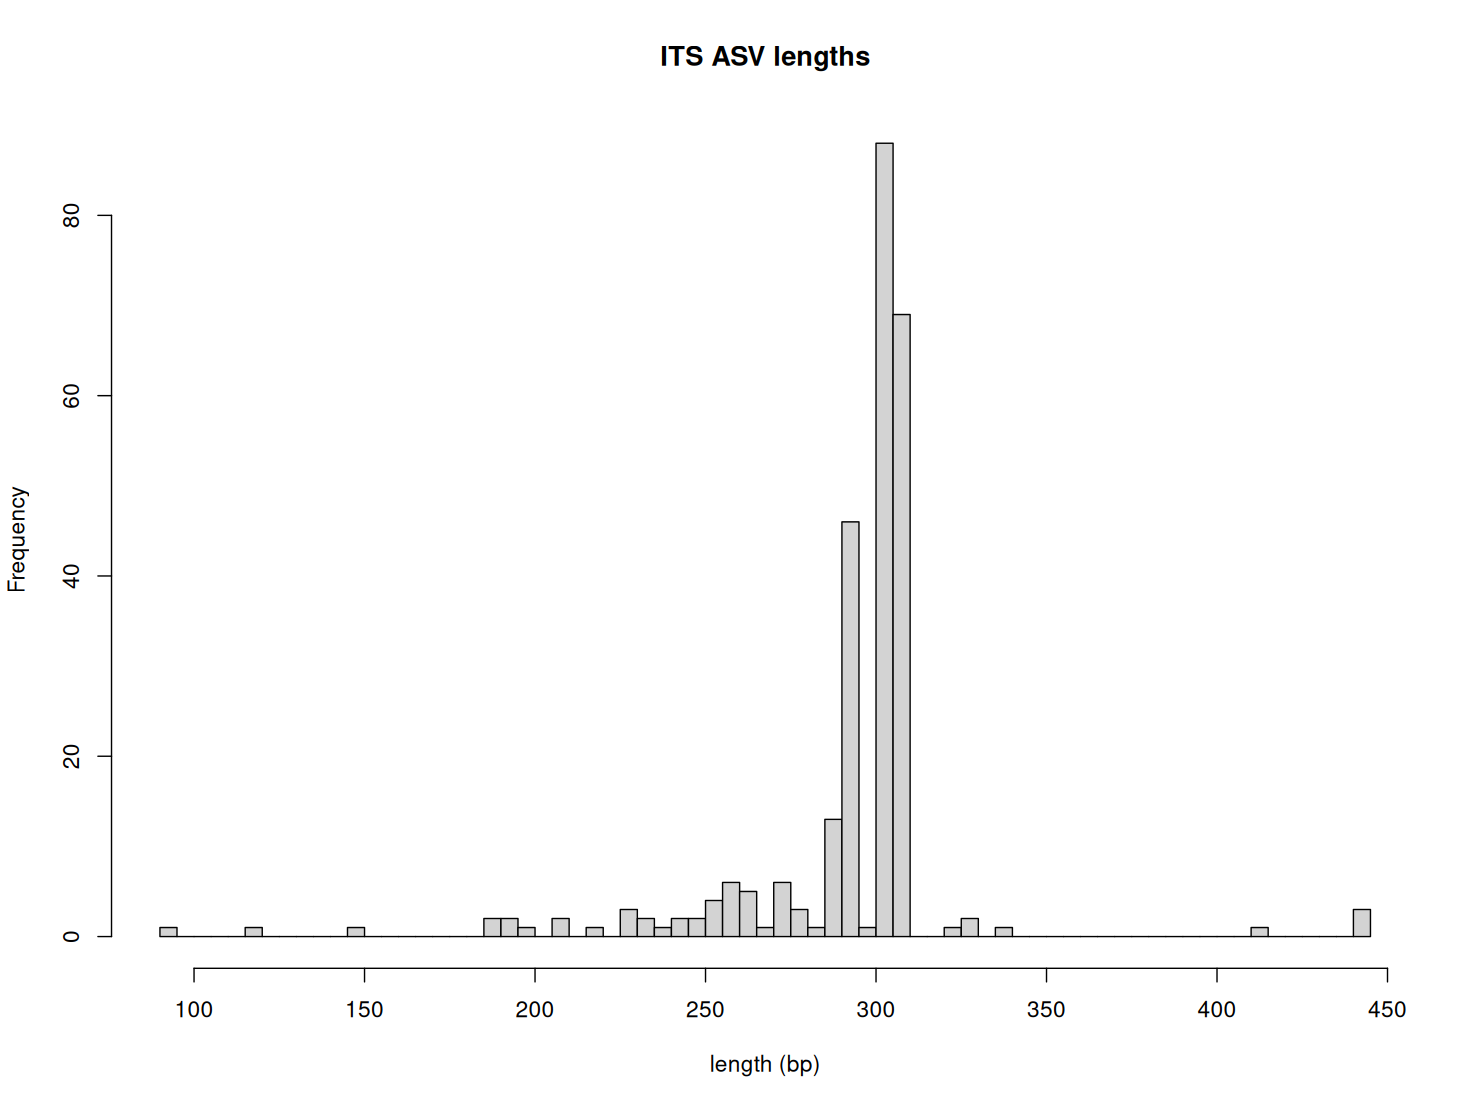

In [8]:
# 16s
seqtab.16s <- makeSequenceTable(mergers.16s)
dim(seqtab.16s)                                    # samples x ASVs
table(nchar(getSequences(seqtab.16s)))             # number of ASVs of each length

seqtab.16s <- seqtab.16s[, nchar(colnames(seqtab.16s)) %in% seqLenRange.16s]
dim(seqtab.16s)                                    # ASVs left after the length filter

# ITS
seqtab.ITS <- makeSequenceTable(mergers.ITS)
dim(seqtab.ITS)
hist(nchar(getSequences(seqtab.ITS)), breaks = 50,
     main = "ITS ASV lengths", xlab = "length (bp)")

### remove chimeras
- **chimeras** are PCR artifacts: an extension stops partway, and the half-made strand primes off a *different* template in the next cycle, giving a sequence that is half one organism and half another
- `removeBimeraDenovo` flags an ASV as a chimera (a "bimera", 2 parents) if it can be rebuilt exactly from a left piece of one more abundant ASV plus a right piece of another. "de novo" = parents come from the data itself, not a reference database
- `method = "consensus"` (default): check each sample separately, then call an ASV chimeric if it's flagged in most of the samples it appears in
- it's normal for a large % of ASVs to be chimeric, but they should be a small % of **reads**. Chimeras are mostly rare. If a lot of reads are lost here, something upstream is usually wrong (e.g. primers not fully removed)

In [9]:
# 16s
seqtab.nochim.16s <- removeBimeraDenovo(seqtab.16s, method = chimeraMethod, multithread = nThreads, verbose = TRUE)
dim(seqtab.nochim.16s)
sum(seqtab.nochim.16s) / sum(seqtab.16s)   # fraction of READS that were not chimeric

# ITS
seqtab.nochim.ITS <- removeBimeraDenovo(seqtab.ITS, method = chimeraMethod, multithread = nThreads, verbose = TRUE)
dim(seqtab.nochim.ITS)
sum(seqtab.nochim.ITS) / sum(seqtab.ITS)

# save the ASV tables, the main product of dada2 (taxonomy is added in stage 3)
saveRDS(seqtab.nochim.16s, file.path(procPath, "16S", "seqtab_nochim_16S.rds"))
saveRDS(seqtab.nochim.ITS, file.path(procPath, "ITS", "seqtab_nochim_ITS.rds"))

Identified 2 bimeras out of 251 input sequences.
Identified 43 bimeras out of 272 input sequences.


### track reads through the pipeline
How many reads each sample has left after every step. This is the main check that the pipeline worked: look for **one step** where reads suddenly drop.
- big loss at `filtered`: `maxEE` / `truncLen` too strict
- big loss at `merged`: reads too short to overlap (16S: `truncLen` too short; ITS: long amplicons)
- big loss at `nonchim`: often leftover primers
- samples dropped earlier in the pipeline show 0 for the later steps

In [10]:
getN <- function(x) sum(getUniques(x))   # total reads in a dada or mergePairs result

# counts before denoising are passed in as a data frame (one row per sample, named by sample);
# this function adds the dada2 steps as extra columns (0 for samples that were dropped along the way)
trackReads <- function(earlyCounts, dadaFs, dadaRs, mergers, seqtabNochim) {
    track <- earlyCounts
    track$denoisedF <- 0
    track$denoisedR <- 0
    track$merged    <- 0
    track$nonchim   <- 0
    track[names(dadaFs), "denoisedF"] <- sapply(dadaFs, getN)
    track[names(dadaRs), "denoisedR"] <- sapply(dadaRs, getN)
    track[names(mergers), "merged"]   <- sapply(mergers, getN)
    track[rownames(seqtabNochim), "nonchim"] <- rowSums(seqtabNochim)
    track$percentKept <- round(100 * track$nonchim / track[, 1], 1)
    return(track)
}

# 16s: filterAndTrim output has one row per input file, in the same order as sample.names.16s
early.16s <- data.frame(row.names = sample.names.16s,
                        input     = filtOut.16s[, "reads.in"],
                        filtered  = filtOut.16s[, "reads.out"])
track.16s <- trackReads(early.16s, dadaFs.16s, dadaRs.16s, mergers.16s, seqtab.nochim.16s)

# ITS has 2 extra steps (N removal, cutadapt) before filtering
early.ITS <- data.frame(row.names = sample.names.ITS,
                        input     = filtN.ITS[, "reads.in"],
                        noN       = filtN.ITS[, "reads.out"],
                        cutadapt  = 0,
                        filtered  = 0)
early.ITS[sample.names.ITS[hasCut.ITS], "cutadapt"] <- filtOut.ITS[, "reads.in"]
early.ITS[sample.names.ITS[hasCut.ITS], "filtered"] <- filtOut.ITS[, "reads.out"]
track.ITS <- trackReads(early.ITS, dadaFs.ITS, dadaRs.ITS, mergers.ITS, seqtab.nochim.ITS)

# add sample type so controls are easy to spot
track.16s$sampleType <- sampData.16s[rownames(track.16s), "sampleType"]
track.ITS$sampleType <- sampData.ITS[rownames(track.ITS), "sampleType"]

head(track.16s)
head(track.ITS)
summary(track.16s$percentKept)
summary(track.ITS$percentKept)

write.csv(track.16s, file.path(resPath, "readTracking_16S.csv"))
write.csv(track.ITS, file.path(resPath, "readTracking_ITS.csv"))

In [11]:
summary(track.ITS$percentKept)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   9.70   87.40   90.50   87.92   91.60   93.60 

## taxonomy
### assign taxonomy (naive Bayesian classifier)
- `assignTaxonomy` is dada2's version of the RDP **naive Bayesian classifier (NBC)**. It breaks each ASV into all its 8-letter "words" (k-mers) and asks which genus in the training set those words most likely came from
- **bootstrapping:** it repeats the call 100 times, each time using a random 1/8 of the k-mers. A rank (e.g. genus) is only reported if it was the answer in >= `minBoot` of the 100 runs (default 50). Otherwise it's left `NA`. So `NA` at genus = "not confident", not "unknown organism"
- the classifier can only ever answer with a label that's **in the training set**. That's why it needs a big, general reference database rather than the authors' small set of inoculum sequences (those are used further down to flag inoculum ASVs instead)
- **16S:** SILVA 138.2 (dada2-formatted). Species are added separately by `addSpecies`, which only assigns a species on a **100% exact match**, because ~250 bp of 16S usually can't tell species apart reliably
- **ITS:** UNITE. We use the **"all eukaryotes"** version, not fungi-only: plant (*Astragalus*) ITS reads then get labelled as plants and can be removed. With a fungi-only database, the classifier would force them onto the closest fungus
- the paper used RDP v16 (16S) and UNITE v7.2 (ITS) with SINTAX, so names won't line up 100% with theirs

### databases (download once)
- **SILVA:** the next cell downloads it automatically if it's not already in `data/databases/` (~130 MB)
- **UNITE** has to be downloaded by hand, because it sits behind a web form:
    1. go to https://unite.ut.ee/repository.php -> **"General FASTA release"**
    2. pick the newest release for **all eukaryotes** (the file name contains `_all_`, e.g. `sh_general_release_dynamic_all_<date>.fasta`)
    3. unzip it into `data/databases/`
    4. put the exact file name in `uniteRef` in the parameter cell, and write down the version/date (reproducibility!)

In [ ]:
dir.create(dbPath, recursive = TRUE, showWarnings = FALSE)

# SILVA: download if missing
for (f in c(silvaTrainset, silvaSpecies)) {
    if (!file.exists(f)) download.file(paste0(silvaURL, basename(f), "?download=1"), f, mode = "wb")
}

# UNITE: stop with a clear message if it hasn't been downloaded yet
if (!file.exists(uniteRef)) stop("UNITE file not found: download it (see markdown above) and set uniteRef in the parameter cell")

file.info(c(silvaTrainset, silvaSpecies, uniteRef))[, c("size", "mtime")]   # sizes + dates, for your notes

In [ ]:
# 16s (slow: tens of minutes for a few thousand ASVs)
tax16s.out <- assignTaxonomy(seqtab.nochim.16s, silvaTrainset, minBoot = minBoot,
                             outputBootstraps = TRUE, multithread = nThreads)
taxa.16s <- tax16s.out$tax        # taxonomy: one row per ASV, one column per rank
boot.16s <- tax16s.out$boot       # bootstrap confidence for each rank (useful to check how sure it was)
taxa.16s <- addSpecies(taxa.16s, silvaSpecies)

# ITS
taxITS.out <- assignTaxonomy(seqtab.nochim.ITS, uniteRef, minBoot = minBoot,
                             outputBootstraps = TRUE, multithread = nThreads)
taxa.ITS <- taxITS.out$tax
boot.ITS <- taxITS.out$boot
taxa.ITS[] <- gsub("^[kpcofgs]__", "", taxa.ITS)   # UNITE names look like "k__Fungi"; remove the "k__" prefixes ([] keeps it a matrix)

saveRDS(list(tax = taxa.16s, boot = boot.16s), file.path(procPath, "16S", "taxonomy_16S.rds"))
saveRDS(list(tax = taxa.ITS, boot = boot.ITS), file.path(procPath, "ITS", "taxonomy_ITS.rds"))

# look at a few (row names are the full sequences, so remove them for printing)
taxa.print <- taxa.16s
rownames(taxa.print) <- NULL
head(taxa.print)
taxa.print <- taxa.ITS
rownames(taxa.print) <- NULL
head(taxa.print)

### remove non-target reads (host, chloroplast, mitochondria)
- leaves are full of plant DNA. Chloroplasts and mitochondria are descended from bacteria, so 16S primers amplify them too. The PNA clamps reduce this but don't stop it
- **16S keep:** Kingdom = Bacteria or Archaea, AND Order is not `Chloroplast`, AND Family is not `Mitochondria` (SILVA puts chloroplasts in Cyanobacteria and mitochondria in Rickettsiales)
- **ITS keep:** Kingdom = Fungi (drops plant reads and other eukaryotes)
- ASVs with no Kingdom assignment (`NA`) are dropped too: if the classifier can't even confidently say "Bacteria", it's usually off-target junk
- the cell first counts **reads** in each category, so you can see how much of the data was host DNA. Compare the `_noPNA` samples with their PNA partners (e.g. `31c_noPNA` vs `31a` / `31b`)

In [ ]:
# label each ASV with what kind of sequence it is
classify16S <- function(taxa) {
    category <- rep("bacteria/archaea", nrow(taxa))
    category[!(taxa[, "Kingdom"] %in% c("Bacteria", "Archaea"))] <- "non-bacterial/unassigned"
    category[taxa[, "Order"]  %in% "Chloroplast"]  <- "chloroplast"
    category[taxa[, "Family"] %in% "Mitochondria"] <- "mitochondria"
    names(category) <- rownames(taxa)
    return(category)
}
classifyITS <- function(taxa) {
    category <- rep("other eukaryote/unassigned", nrow(taxa))
    category[taxa[, "Kingdom"] %in% "Fungi"]         <- "fungi"
    category[taxa[, "Kingdom"] %in% "Viridiplantae"] <- "plant"
    names(category) <- rownames(taxa)
    return(category)
}

category.16s <- classify16S(taxa.16s)
category.ITS <- classifyITS(taxa.ITS)

# number of READS (not ASVs) in each category, all samples together
tapply(colSums(seqtab.nochim.16s), category.16s[colnames(seqtab.nochim.16s)], sum)
tapply(colSums(seqtab.nochim.ITS), category.ITS[colnames(seqtab.nochim.ITS)], sum)

# reads per category for the PNA vs noPNA samples
pnaSamples <- c("134a", "134b", "134c_noPNA", "31a", "31b", "31c_noPNA",
                "186a", "186b", "186c_noPNA", "192a", "192b", "192c_noPNA", "260a", "260b", "260c_noPNA")
pnaRows <- rownames(sampData.16s)[sampData.16s$sampleName %in% pnaSamples & rownames(sampData.16s) %in% rownames(seqtab.nochim.16s)]
pnaTable <- t(apply(seqtab.nochim.16s[pnaRows, , drop = FALSE], 1, function(x) tapply(x, category.16s[colnames(seqtab.nochim.16s)], sum)))
rownames(pnaTable) <- sampData.16s[pnaRows, "sampleName"]
pnaTable[order(rownames(pnaTable)), ]

# keep only target ASVs
seqtab.clean.16s <- seqtab.nochim.16s[, category.16s[colnames(seqtab.nochim.16s)] == "bacteria/archaea"]
seqtab.clean.ITS <- seqtab.nochim.ITS[, category.ITS[colnames(seqtab.nochim.ITS)] == "fungi"]
dim(seqtab.clean.16s)
dim(seqtab.clean.ITS)

### remove contaminants (negative control)
- the extraction/PCR negative control (`neg_control`, plate 2 well h12) should have no DNA. Anything sequenced from it came from reagents, the lab, or another well (cross-contamination)
- **rule (same as the paper):** for each ASV, what fraction of its total reads is in the negative control? If > `contamThreshold` (5%), it's treated as a contaminant and removed from **all** samples
    - a real leaf microbe has thousands of reads across plants and only a few in the blank, so it survives
    - a reagent contaminant has a large share of its reads in the blank, so it's removed
- this is a simple, transparent rule. The `decontam` R package is a more formal alternative (not installed, not used here). The paper notes that removing *everything* found in blanks is too strict
- control samples (negative, positive, isolates, inoculum) are **kept** in the table and labelled in `sampleType`, so you can subset them out (or look at them) later

In [ ]:
removeContaminants <- function(seqtab, negSamples, threshold) {
    negSamples <- intersect(negSamples, rownames(seqtab))
    if (length(negSamples) == 0) {
        message("no negative control left in this table (it may have lost all reads), so nothing removed")
        return(list(seqtab = seqtab, contaminants = character(0)))
    }
    negReads   <- colSums(seqtab[negSamples, , drop = FALSE])   # reads of each ASV in the negative control(s)
    totalReads <- colSums(seqtab)                               # reads of each ASV in all samples
    fracInNeg  <- negReads / totalReads
    isContam   <- fracInNeg > threshold
    return(list(seqtab = seqtab[, !isContam, drop = FALSE],
                contaminants = colnames(seqtab)[isContam],
                fracInNeg = fracInNeg))
}

negSamples.16s <- rownames(sampData.16s)[sampData.16s$sampleType == "negControl"]
negSamples.ITS <- rownames(sampData.ITS)[sampData.ITS$sampleType == "negControl"]

contam.16s <- removeContaminants(seqtab.clean.16s, negSamples.16s, contamThreshold)
contam.ITS <- removeContaminants(seqtab.clean.ITS, negSamples.ITS, contamThreshold)

length(contam.16s$contaminants)   # number of ASVs removed
length(contam.ITS$contaminants)
taxa.16s[contam.16s$contaminants, c("Phylum", "Family", "Genus"), drop = FALSE]   # who were they?
taxa.ITS[contam.ITS$contaminants, c("Phylum", "Family", "Genus"), drop = FALSE]

seqtab.final.16s <- contam.16s$seqtab
seqtab.final.ITS <- contam.ITS$seqtab

### match ASVs to the inoculum & *A. fulva* sequences from the paper's repo
These are the repo FASTA files, used as a **reference to compare against**, not as classifier training data:
- `all_16S_OTUs_inoculum...fasta` (260 OTUs) and `all_ITS_OTUs_inoculum...fasta` (20 OTUs): sequences the authors found in the sprayed inoculum
- `alternaria_fulva.fasta`: the *A. fulva* ITS sequence from GenBank (JX827264.1, filed as *Undifilum*). It covers 18S-ITS1-5.8S-ITS2-28S, much longer than our ITS1 ASVs

**how: `vsearch --usearch_global`** (the same kind of search the paper used)
- every ASV (query) is aligned against every reference sequence (database), and the single best hit is reported
- an ASV counts as a **match** if best identity >= `minIdentity` (97%). Hits down to `vsearchReportId` (80%) are still reported, so you can see near-misses (e.g. 95-96%)
- flags used:
    - `--id 0.80`: only report hits >= 80% identity
    - `--query_cov 0.90`: >= 90% of the ASV must be in the alignment
    - `--maxaccepts 0 --maxrejects 0`: compare against *every* reference instead of stopping at the first good one (exhaustive; fine with a few hundred references)
    - `--maxhits 1`: keep only the best hit
    - `--blast6out`: write results as a tab-separated table (BLAST "format 6")
- vsearch's default identity ignores **terminal gaps** (overhangs at the ends). That's why a 250 bp ASV can score 100% inside the long *A. fulva* sequence, and it's also why `--query_cov` is needed
- the query/reference FASTAs and hit tables are written to `data/processed/{16S,ITS}/vsearch/`, so you can open them
- the result is new columns in the taxonomy table: `inoculumOTU`, `inoculumPID`, `inoculumMatch` (and `AfulvaPID`, `AfulvaMatch` for ITS)

In [ ]:
# vsearch must be installed for this step (see install cell)
if (!file.exists(vsearchPath)) stop("vsearch not found at vsearchPath - install it first (see install cell)")

# download the reference FASTAs from the authors' repo once
dir.create(refPath, recursive = TRUE, showWarnings = FALSE)
for (f in c(inocRef.16s, inocRef.ITS, afulvaRef)) {
    if (!file.exists(f)) download.file(paste0(repoURL, basename(f)), f)
}

refs.16s    <- readDNAStringSet(inocRef.16s)
refs.ITS    <- readDNAStringSet(inocRef.ITS)
refs.Afulva <- readDNAStringSet(afulvaRef)
names(refs.16s)    <- sub("^centroid=([^;]+);.*$", "\\1", names(refs.16s))   # "centroid=Otu380;seqs=1;size=24" -> "Otu380"
names(refs.Afulva) <- "Afulva_JX827264.1"                                    # shorter than the GenBank description
length(refs.16s)
length(refs.ITS)

# for each ASV: best hit among the reference sequences, using vsearch
matchWithVsearch <- function(asvSeqs, refSeqs, label, workDir,
                             minIdentity, reportId, queryCov, vsearch, threads) {
    dir.create(workDir, recursive = TRUE, showWarnings = FALSE)
    queryFile <- file.path(workDir, paste0(label, "_queries.fasta"))
    dbFile    <- file.path(workDir, paste0(label, "_refs.fasta"))
    hitFile   <- file.path(workDir, paste0(label, "_hits.tsv"))

    # write ASVs with short temporary names (seq1, seq2, ...) and the cleaned-up references
    asvSet <- DNAStringSet(asvSeqs)
    names(asvSet) <- paste0("seq", seq_along(asvSeqs))
    writeXStringSet(asvSet, queryFile)
    writeXStringSet(refSeqs, dbFile)

    # run vsearch (shQuote because our folder names have spaces)
    system2(vsearch, args = c("--usearch_global", shQuote(queryFile),
                              "--db", shQuote(dbFile),
                              "--id", reportId,
                              "--query_cov", queryCov,
                              "--maxaccepts", 0, "--maxrejects", 0, "--maxhits", 1,
                              "--blast6out", shQuote(hitFile),
                              "--threads", threads, "--quiet"))

    # start with "no hit" for every ASV, then fill in the ones vsearch found
    result <- data.frame(bestRef = NA, bestPID = 0, row.names = asvSeqs)
    if (file.exists(hitFile) && file.size(hitFile) > 0) {
        hits <- read.table(hitFile, sep = "\t", header = FALSE)   # columns: query, target, % identity, ...
        hitRows <- asvSeqs[as.integer(sub("^seq", "", hits$V1))]  # "seq12" -> 12th ASV
        result[hitRows, "bestRef"] <- hits$V2
        result[hitRows, "bestPID"] <- hits$V3
    }
    result$match <- result$bestPID >= minIdentity
    return(result)
}

inocMatch.16s <- matchWithVsearch(colnames(seqtab.final.16s), refs.16s, "inoculum16S",
                                  file.path(procPath, "16S", "vsearch"),
                                  minIdentity, vsearchReportId, queryCov, vsearchPath, nThreads)
inocMatch.ITS <- matchWithVsearch(colnames(seqtab.final.ITS), refs.ITS, "inoculumITS",
                                  file.path(procPath, "ITS", "vsearch"),
                                  minIdentity, vsearchReportId, queryCov, vsearchPath, nThreads)
afulvaMatch.ITS <- matchWithVsearch(colnames(seqtab.final.ITS), refs.Afulva, "afulvaITS",
                                    file.path(procPath, "ITS", "vsearch"),
                                    minIdentity, vsearchReportId, queryCov, vsearchPath, nThreads)

table(inocMatch.16s$match)     # how many ASVs match an inoculum OTU
table(inocMatch.ITS$match)
table(afulvaMatch.ITS$match)   # how many ASVs match A. fulva

### build phyloseq objects & save
- **phyloseq** bundles everything for downstream analysis into one R object:
    - `otu_table`: ASV counts per sample
    - `tax_table`: taxonomy + the inoculum / *A. fulva* match columns
    - `sample_data`: plate, well, sample type, plant, treatment, `inoculum`, `Afulva`
    - `refseq`: the ASV sequences
- ASVs get short names (`ASV16S_1`, `ASVITS_1`, ...) instead of the full sequence. The sequences are kept in `refseq` and in the exported FASTA
- the read-tracking tables from stage 2 get 2 more columns (after host removal, after contaminant removal) and are saved again
- **outputs:**
    - `data/processed/{16S,ITS}/phyloseq_*.rds`: load with `readRDS()` in the analysis notebook
    - `results/ASVtable_*.csv`: counts + taxonomy, readable in Excel
    - `results/ASVs_*.fasta`: ASV sequences
    - `results/readTracking_*.csv`: updated

In [ ]:
buildPhyloseq <- function(seqtab, taxa, matchTable, sampData, prefix) {
    asvSeqs <- colnames(seqtab)
    taxMat  <- cbind(taxa[asvSeqs, , drop = FALSE], as.matrix(matchTable[asvSeqs, , drop = FALSE]))  # add match columns to taxonomy
    ps <- phyloseq(otu_table(seqtab, taxa_are_rows = FALSE),
                   tax_table(taxMat),
                   sample_data(sampData[rownames(seqtab), ]))
    dna <- DNAStringSet(taxa_names(ps))   # keep the sequences ...
    names(dna) <- taxa_names(ps)
    ps <- merge_phyloseq(ps, dna)
    taxa_names(ps) <- paste0(prefix, seq(ntaxa(ps)))   # ... then give ASVs short names
    return(ps)
}

# match columns: inoculum for both loci, plus A. fulva for ITS
match.16s <- data.frame(inoculumOTU = inocMatch.16s$bestRef, inoculumPID = inocMatch.16s$bestPID,
                        inoculumMatch = ifelse(inocMatch.16s$match, "yes", "no"),
                        row.names = rownames(inocMatch.16s))
match.ITS <- data.frame(inoculumOTU = inocMatch.ITS$bestRef, inoculumPID = inocMatch.ITS$bestPID,
                        inoculumMatch = ifelse(inocMatch.ITS$match, "yes", "no"),
                        AfulvaPID = afulvaMatch.ITS$bestPID,
                        AfulvaMatch = ifelse(afulvaMatch.ITS$match, "yes", "no"),
                        row.names = rownames(inocMatch.ITS))

ps.16s <- buildPhyloseq(seqtab.final.16s, taxa.16s, match.16s, sampData.16s, "ASV16S_")
ps.ITS <- buildPhyloseq(seqtab.final.ITS, taxa.ITS, match.ITS, sampData.ITS, "ASVITS_")
ps.16s
ps.ITS

In [ ]:
# phyloseq objects (main input for downstream analysis)
saveRDS(ps.16s, file.path(procPath, "16S", "phyloseq_16S.rds"))
saveRDS(ps.ITS, file.path(procPath, "ITS", "phyloseq_ITS.rds"))

# ASV table + taxonomy as CSV (ASVs as rows, samples as columns)
exportASVtable <- function(ps, file) {
    counts <- t(as(otu_table(ps), "matrix"))
    out <- data.frame(ASV = taxa_names(ps), as(tax_table(ps), "matrix"), counts, check.names = FALSE)
    write.csv(out, file, row.names = FALSE)
}
exportASVtable(ps.16s, file.path(resPath, "ASVtable_16S.csv"))
exportASVtable(ps.ITS, file.path(resPath, "ASVtable_ITS.csv"))

# ASV sequences as FASTA
writeXStringSet(refseq(ps.16s), file.path(resPath, "ASVs_16S.fasta"))
writeXStringSet(refseq(ps.ITS), file.path(resPath, "ASVs_ITS.fasta"))

# finish the read-tracking tables: reads left after host removal and after contaminant removal
track.16s$targetOnly <- 0
track.16s[rownames(seqtab.clean.16s), "targetOnly"] <- rowSums(seqtab.clean.16s)
track.16s$noContam <- 0
track.16s[rownames(seqtab.final.16s), "noContam"] <- rowSums(seqtab.final.16s)
track.ITS$targetOnly <- 0
track.ITS[rownames(seqtab.clean.ITS), "targetOnly"] <- rowSums(seqtab.clean.ITS)
track.ITS$noContam <- 0
track.ITS[rownames(seqtab.final.ITS), "noContam"] <- rowSums(seqtab.final.ITS)

write.csv(track.16s, file.path(resPath, "readTracking_16S.csv"))
write.csv(track.ITS, file.path(resPath, "readTracking_ITS.csv"))
summary(track.16s$noContam[track.16s$sampleType == "plant"])   # final reads per plant sample
summary(track.ITS$noContam[track.ITS$sampleType == "plant"])

sessionInfo()   # package versions, for reproducibility

## end of the dada2 pipeline
Outputs are `data/processed/16S/phyloseq_16S.rds` and `data/processed/ITS/phyloseq_ITS.rds`.

Downstream analysis (diversity, ordination, differential abundance between treatments) should go in a **separate notebook** that starts with `readRDS()` of these files. That way plots can be remade without rerunning dada2. Things to decide there:
- drop control samples (`sampleType != "plant"`), samples with very few reads, and plants with `plantStatus` = `dead` / `dontuse`?
- the repeated samples of one plant (`a`/`b`/`c_noPNA`): merge them or pick one per plant, so a plant isn't counted twice
- normalization: rarefying vs. relative abundance vs. a model-based method (the paper used an internal standard + Bayesian Dirichlet-multinomial models). This MiSeq run has no internal standard